<a href="https://colab.research.google.com/github/daniloc9208/streaming_churn/blob/master/estatistica_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Univariada

In [9]:
from google.colab import drive
import pandas as pd
import os

# Montar o Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
import os
import pandas as pd

def localizar_e_carregar():
    print("Buscando o arquivo 'clientes_base.csv' no Google Drive dinamicamente...")
    caminho_encontrado = None

    for raiz, diretorios, arquivos in os.walk('/content/drive'):
        if 'clientes_base.csv' in arquivos:
            caminho_encontrado = os.path.join(raiz, 'clientes_base.csv')
            break

    if caminho_encontrado:
        print(f"Arquivo localizado com sucesso em: {caminho_encontrado}")
        df_temp = pd.read_csv(caminho_encontrado)
        print("DataFrame carregado com sucesso!")
        return df_temp
    else:
        raise FileNotFoundError("Não foi possível encontrar o arquivo 'clientes_base.csv' no seu Google Drive. Certifique-se de que ele foi enviado ao Drive correspondente.")

try:
    df = localizar_e_carregar()
    print("\n--- Tipos das Colunas ---")
    display(df.dtypes)
except Exception as e:
    print(f"Erro: {e}")


Buscando o arquivo 'clientes_base.csv' no Google Drive dinamicamente...
Arquivo localizado com sucesso em: /content/drive/MyDrive/UNIPDS/Business_Analytics/Estatística/clientes_base.csv
DataFrame carregado com sucesso!

--- Tipos das Colunas ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,object
data_cancelamento,object


In [12]:
# Identificar os nomes exatos das colunas no DataFrame
print("Colunas disponíveis:", df.columns.tolist())

Colunas disponíveis: ['cliente_id', 'idade', 'plano', 'ciclo', 'valor_mensal', 'regiao', 'canal_aquisicao', 'nps', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'motivo_cancelamento', 'churn']



=== Distribuição de Plano (plano) ===


,count
plano,
Basico,2062
Padrao,1965
Premium,998


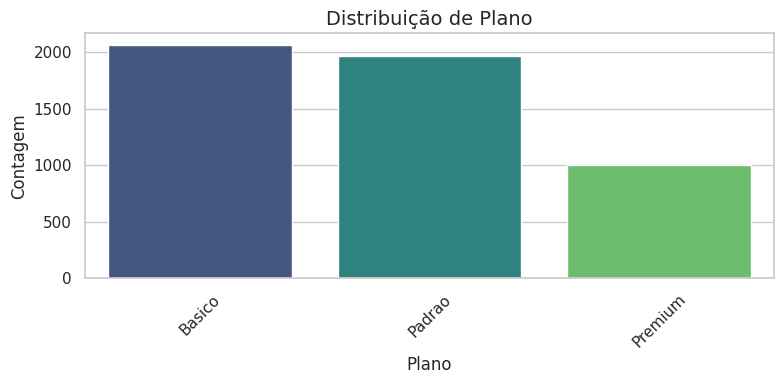


=== Distribuição de Ciclo (ciclo) ===


,count
ciclo,
Mensal,3794
Anual,1231


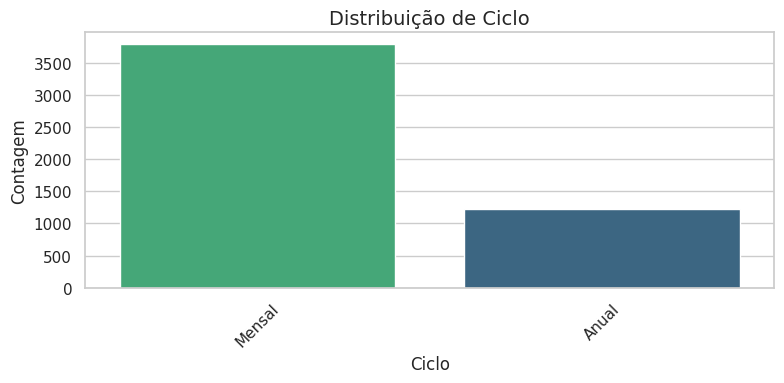


=== Distribuição de Região (regiao) ===


,count
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-oeste,488
Norte,408
?,170


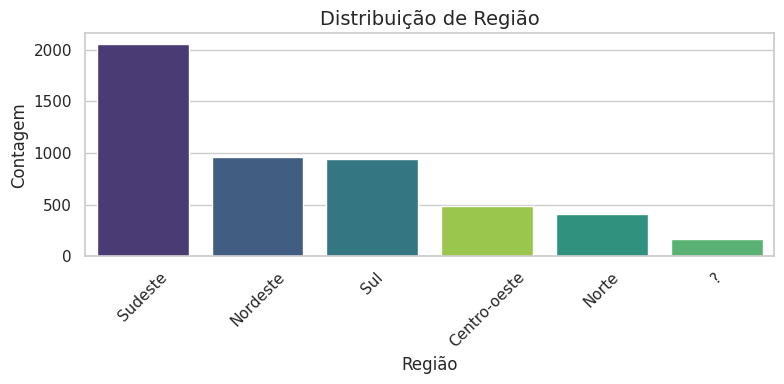


=== Distribuição de Canal de Aquisição (canal_aquisicao) ===


,count
canal_aquisicao,
Organico,1510
Indicacao,1082
Instagram,1018
Google,886
Ig,529


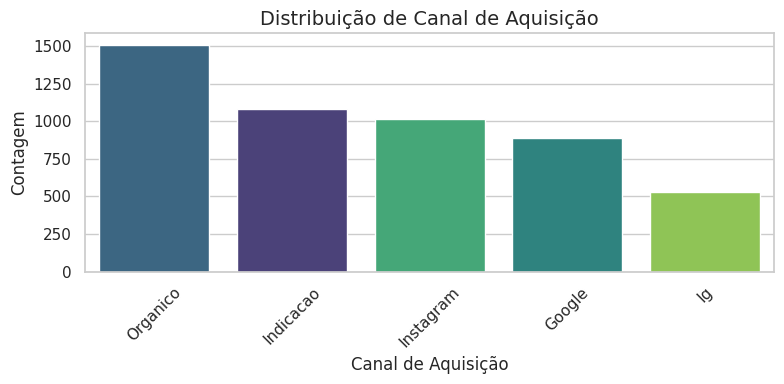

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Padronização e Limpeza dos Dados
df_cleaned = df.copy()

def normalizar_texto(texto):
    if pd.isna(texto):
        return texto
    texto = str(texto).strip().lower()
    # Remover acentos comuns
    substituicoes = {
        'á': 'a', 'ã': 'a', 'â': 'a', 'à': 'a',
        'é': 'e', 'ê': 'e',
        'í': 'i',
        'ó': 'o', 'õ': 'o', 'ô': 'o',
        'ú': 'u',
        'ç': 'c'
    }
    for k, v in substituicoes.items():
        texto = texto.replace(k, v)
    return texto.capitalize()

# Corrigindo as colunas de interesse
df_cleaned['plano'] = df_cleaned['plano'].apply(normalizar_texto)
df_cleaned['ciclo'] = df_cleaned['ciclo'].apply(normalizar_texto)
df_cleaned['regiao'] = df_cleaned['regiao'].apply(normalizar_texto)
df_cleaned['canal_aquisicao'] = df_cleaned['canal_aquisicao'].apply(normalizar_texto)

# Colunas que vamos analisar
colunas_analise = {
    'plano': 'Plano',
    'ciclo': 'Ciclo',
    'regiao': 'Região',
    'canal_aquisicao': 'Canal de Aquisição'
}

# 2. Exibição das contagens e plotagem dos gráficos padronizados
sns.set_theme(style="whitegrid")

for col_real, col_nome_amigavel in colunas_analise.items():
    if col_real in df_cleaned.columns:
        print(f"\n=== Distribuição de {col_nome_amigavel} ({col_real}) ===")
        contagem = df_cleaned[col_real].value_counts(dropna=False)
        display(contagem.to_frame())

        # Criar o gráfico de barras
        plt.figure(figsize=(8, 4))
        sns.countplot(
            data=df_cleaned,
            x=col_real,
            order=contagem.index,
            hue=col_real,
            legend=False,
            palette="viridis"
        )
        plt.title(f"Distribuição de {col_nome_amigavel}", fontsize=14)
        plt.xlabel(col_nome_amigavel, fontsize=12)
        plt.ylabel("Contagem", fontsize=12)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print(f"A coluna '{col_real}' não foi encontrada no DataFrame.")

In [14]:
import numpy as np

# 1 - Quantos nulos tem nas colunas?
print("=== 1 - Quantidade de valores nulos por coluna ===")
nulos_por_coluna = df_cleaned.isnull().sum()
display(nulos_por_coluna.to_frame(name='Total de Nulos'))

# 2 - Mostre um exemplo do dataframe para quando a coluna é '?'
print("\n=== 2 - Exemplo de linhas contendo '?' em qualquer coluna ===")
# Procurando o caractere '?' nas colunas de texto (string/object)
colunas_texto = df_cleaned.select_dtypes(include=['object']).columns
linhas_com_interrogacao = df_cleaned[df_cleaned[colunas_texto].apply(lambda x: x.astype(str).str.contains('\\?', regex=True)).any(axis=1)]

if len(linhas_com_interrogacao) > 0:
    display(linhas_com_interrogacao.head())
else:
    print("Nenhuma linha contendo o caractere '?' foi encontrada nas colunas de texto.")

# 3 - A coluna canal de aquisição, substitua ig por Instagram
print("\n=== 3 - Substituindo 'Ig' por 'Instagram' na coluna canal_aquisicao ===")
# Verificando a distribuição antes da substituição
print("Antes da substituição:")
print(df_cleaned['canal_aquisicao'].value_counts())

# Realizando a substituição (tratando com minúsculas/maiúsculas caso necessário devido à nossa padronização anterior)
df_cleaned['canal_aquisicao'] = df_cleaned['canal_aquisicao'].replace({'Ig': 'Instagram', 'ig': 'Instagram'})

print("\nDepois da substituição:")
print(df_cleaned['canal_aquisicao'].value_counts())

=== 1 - Quantidade de valores nulos por coluna ===


,Total de Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509



=== 2 - Exemplo de linhas contendo '?' em qualquer coluna ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,Instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,Basico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrao,Anual,3490.0,?,Organico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,Padrao,Mensal,34.9,?,Google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrao,Mensal,3490.0,?,Organico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0



=== 3 - Substituindo 'Ig' por 'Instagram' na coluna canal_aquisicao ===
Antes da substituição:
canal_aquisicao
Organico     1510
Indicacao    1082
Instagram    1018
Google        886
Ig            529
Name: count, dtype: int64

Depois da substituição:
canal_aquisicao
Instagram    1547
Organico     1510
Indicacao    1082
Google        886
Name: count, dtype: int64


In [15]:
import numpy as np

# Substituir o caractere '?' por NaN (nulo) em todo o DataFrame
df_cleaned = df_cleaned.replace('?', np.nan)

print("=== Substituição concluída! ===")
# Verificar a nova contagem de nulos para comprovar que os '?' viraram nulos
nulos_atualizados = df_cleaned.isnull().sum()
display(nulos_atualizados.to_frame(name='Total de Nulos Atualizado'))

=== Substituição concluída! ===


,Total de Nulos Atualizado
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [16]:
# Definir as colunas de data que precisam ser convertidas
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Converter para datetime
for col in colunas_data:
    if col in df_cleaned.columns:
        df_cleaned[col] = pd.to_datetime(df_cleaned[col], errors='coerce')

print("=== Conversão concluída! ===")
# Exibir os tipos das colunas atualizados para confirmar a conversão
display(df_cleaned[colunas_data].dtypes)

=== Conversão concluída! ===


,0
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]
data_ultimo_acesso,datetime64[ns]
data_extracao,datetime64[ns]


In [17]:
import itertools

# Lista das colunas de data convertidas
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Gerar todas as combinações de pares de colunas para calcular a diferença
combinacoes = list(itertools.combinations(colunas_data, 2))

print("=== Calculando diferenças entre as datas (em dias) ===")
for col1, col2 in combinacoes:
    # Nome da nova coluna que guardará a diferença absoluta em dias
    nome_nova_coluna = f"dif_{col1}_vs_{col2}_dias"

    # Calcula a diferença absoluta em dias (tratando valores nulos automaticamente)
    df_cleaned[nome_nova_coluna] = (df_cleaned[col1] - df_cleaned[col2]).dt.days.abs()
    print(f"Coluna criada: {nome_nova_coluna}")

# Exibir uma prévia do DataFrame com as novas colunas criadas
colunas_novas = [f"dif_{c1}_vs_{c2}_dias" for c1, c2 in combinacoes]
display(df_cleaned[colunas_data + colunas_novas].head())

=== Calculando diferenças entre as datas (em dias) ===
Coluna criada: dif_data_assinatura_vs_data_cancelamento_dias
Coluna criada: dif_data_assinatura_vs_data_ultimo_acesso_dias
Coluna criada: dif_data_assinatura_vs_data_extracao_dias
Coluna criada: dif_data_cancelamento_vs_data_ultimo_acesso_dias
Coluna criada: dif_data_cancelamento_vs_data_extracao_dias
Coluna criada: dif_data_ultimo_acesso_vs_data_extracao_dias


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dif_data_assinatura_vs_data_cancelamento_dias,dif_data_assinatura_vs_data_ultimo_acesso_dias,dif_data_assinatura_vs_data_extracao_dias,dif_data_cancelamento_vs_data_ultimo_acesso_dias,dif_data_cancelamento_vs_data_extracao_dias,dif_data_ultimo_acesso_vs_data_extracao_dias
0,2023-04-11,NaT,2024-01-29,2024-01-31,NaN,293.0,295,NaN,NaN,2.0
1,2022-06-02,NaT,2024-01-30,2024-01-31,NaN,607.0,608,NaN,NaN,1.0
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,590.0,1047,17.0,440.0,457.0
3,2023-04-02,NaT,2024-01-13,2024-01-31,NaN,286.0,304,NaN,NaN,18.0
4,2023-04-21,NaT,2024-01-16,2024-01-31,NaN,270.0,285,NaN,NaN,15.0


In [18]:
# 1. Estatísticas descritivas básicas das novas colunas
print("=== Estatísticas Descritivas das Diferenças ===")
display(df_cleaned[colunas_novas].describe())

# 2. Verificação de valores negativos (não devem existir pois usamos .abs())
valores_negativos = (df_cleaned[colunas_novas] < 0).sum()
print("\n=== Quantidade de valores negativos por coluna (Esperado: 0) ===")
display(valores_negativos.to_frame(name='Valores Negativos'))

# 3. Verificação de valores nulos nas novas diferenças
print("\n=== Quantidade de nulos nas novas colunas ===")
# Nota: Diferenças envolvendo 'data_cancelamento' ou 'data_ultimo_acesso' naturalmente terão nulos devido aos dados originais
display(df_cleaned[colunas_novas].isnull().sum().to_frame(name='Valores Nulos'))

=== Estatísticas Descritivas das Diferenças ===


,dif_data_assinatura_vs_data_cancelamento_dias,dif_data_assinatura_vs_data_ultimo_acesso_dias,dif_data_assinatura_vs_data_extracao_dias,dif_data_cancelamento_vs_data_ultimo_acesso_dias,dif_data_cancelamento_vs_data_extracao_dias,dif_data_ultimo_acesso_vs_data_extracao_dias
count,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,220.407652,372.205427,412.432040,21.000666,79.694591,40.451859
std,145.004268,277.082208,270.382969,10.783104,67.851077,55.107192
min,11.000000,0.000000,1.000000,3.000000,3.000000,0.000000
25%,118.000000,163.000000,213.000000,12.000000,30.000000,10.000000
50%,182.500000,307.000000,349.000000,21.000000,60.500000,20.000000
75%,288.500000,512.000000,549.000000,30.000000,107.250000,44.000000
max,1067.000000,1809.000000,1815.000000,137.000000,440.000000,469.000000



=== Quantidade de valores negativos por coluna (Esperado: 0) ===


,Valores Negativos
dif_data_assinatura_vs_data_cancelamento_dias,0
dif_data_assinatura_vs_data_ultimo_acesso_dias,0
dif_data_assinatura_vs_data_extracao_dias,0
dif_data_cancelamento_vs_data_ultimo_acesso_dias,0
dif_data_cancelamento_vs_data_extracao_dias,0
dif_data_ultimo_acesso_vs_data_extracao_dias,0



=== Quantidade de nulos nas novas colunas ===


,Valores Nulos
dif_data_assinatura_vs_data_cancelamento_dias,3509
dif_data_assinatura_vs_data_ultimo_acesso_dias,50
dif_data_assinatura_vs_data_extracao_dias,0
dif_data_cancelamento_vs_data_ultimo_acesso_dias,3524
dif_data_cancelamento_vs_data_extracao_dias,3509
dif_data_ultimo_acesso_vs_data_extracao_dias,50


In [19]:
# 1. Identificar colunas numéricas do DataFrame
colunas_numericas = df_cleaned.select_dtypes(include=['number']).columns.tolist()
print("Colunas numéricas identificadas:", colunas_numericas)

# 2. Obter estatísticas descritivas destas colunas
print("\n=== Estatísticas Descritivas das Colunas Numéricas ===")
display(df_cleaned[colunas_numericas].describe())

# 3. Contar os valores nulos especificamente para as colunas numéricas
print("\n=== Quantidade de Valores Nulos ===")
display(df_cleaned[colunas_numericas].isnull().sum().to_frame(name='Nulos'))

Colunas numéricas identificadas: ['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dif_data_assinatura_vs_data_cancelamento_dias', 'dif_data_assinatura_vs_data_ultimo_acesso_dias', 'dif_data_assinatura_vs_data_extracao_dias', 'dif_data_cancelamento_vs_data_ultimo_acesso_dias', 'dif_data_cancelamento_vs_data_extracao_dias', 'dif_data_ultimo_acesso_vs_data_extracao_dias']

=== Estatísticas Descritivas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dif_data_assinatura_vs_data_cancelamento_dias,dif_data_assinatura_vs_data_ultimo_acesso_dias,dif_data_assinatura_vs_data_extracao_dias,dif_data_cancelamento_vs_data_ultimo_acesso_dias,dif_data_cancelamento_vs_data_extracao_dias,dif_data_ultimo_acesso_vs_data_extracao_dias
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,372.205427,412.432040,21.000666,79.694591,40.451859
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,277.082208,270.382969,10.783104,67.851077,55.107192
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,3.000000,3.000000,0.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,163.000000,213.000000,12.000000,30.000000,10.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,307.000000,349.000000,21.000000,60.500000,20.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,512.000000,549.000000,30.000000,107.250000,44.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,137.000000,440.000000,469.000000



=== Quantidade de Valores Nulos ===


,Nulos
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
dif_data_assinatura_vs_data_cancelamento_dias,3509
dif_data_assinatura_vs_data_ultimo_acesso_dias,50
dif_data_assinatura_vs_data_extracao_dias,0


In [20]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [21]:
# Definindo a coluna alvo
coluna_filtro = 'dif_data_assinatura_vs_data_ultimo_acesso_dias'

# Filtrar: manter valores maiores ou iguais a zero OU valores nulos (NaN)
df_filtered = df_cleaned[(df_cleaned[coluna_filtro] >= 0) | (df_cleaned[coluna_filtro].isnull())]

# Exibir informações de tamanho do dataset antes e depois do filtro
print(f"Quantidade de linhas antes do filtro: {len(df_cleaned)}")
print(f"Quantidade de linhas após o filtro: {len(df_filtered)}")
print(f"Linhas removidas: {len(df_cleaned) - len(df_filtered)}")

# Exibir uma amostra das colunas relevantes do dataset filtrado
display(df_filtered[['data_assinatura', 'data_ultimo_acesso', coluna_filtro]].head())

Quantidade de linhas antes do filtro: 5025
Quantidade de linhas após o filtro: 5025
Linhas removidas: 0


,data_assinatura,data_ultimo_acesso,dif_data_assinatura_vs_data_ultimo_acesso_dias
0,2023-04-11,2024-01-29,293.0
1,2022-06-02,2024-01-30,607.0
2,2021-03-20,2022-10-31,590.0
3,2023-04-02,2024-01-13,286.0
4,2023-04-21,2024-01-16,270.0


In [22]:
# Criar um novo DataFrame filtrado apenas com valores estritamente positivos ou nulos
coluna_filtro = 'dif_data_assinatura_vs_data_ultimo_acesso_dias'
df_positivo_ou_nulo = df_cleaned[(df_cleaned[coluna_filtro] >= 0) | (df_cleaned[coluna_filtro].isnull())].copy()

# Exibir a nova quantidade de linhas
print(f"Linhas no DataFrame original: {len(df_cleaned)}")
print(f"Linhas no novo DataFrame (positivas ou nulas): {len(df_positivo_ou_nulo)}")
print(f"Linhas removidas (que eram zero ou negativas): {len(df_cleaned) - len(df_positivo_ou_nulo)}")

# Visualizar a distribuição para verificação
display(df_positivo_ou_nulo[coluna_filtro].describe().to_frame())

Linhas no DataFrame original: 5025
Linhas no novo DataFrame (positivas ou nulas): 5025
Linhas removidas (que eram zero ou negativas): 0


,dif_data_assinatura_vs_data_ultimo_acesso_dias
count,4975.000000
mean,372.205427
std,277.082208
min,0.000000
25%,163.000000
50%,307.000000
75%,512.000000
max,1809.000000


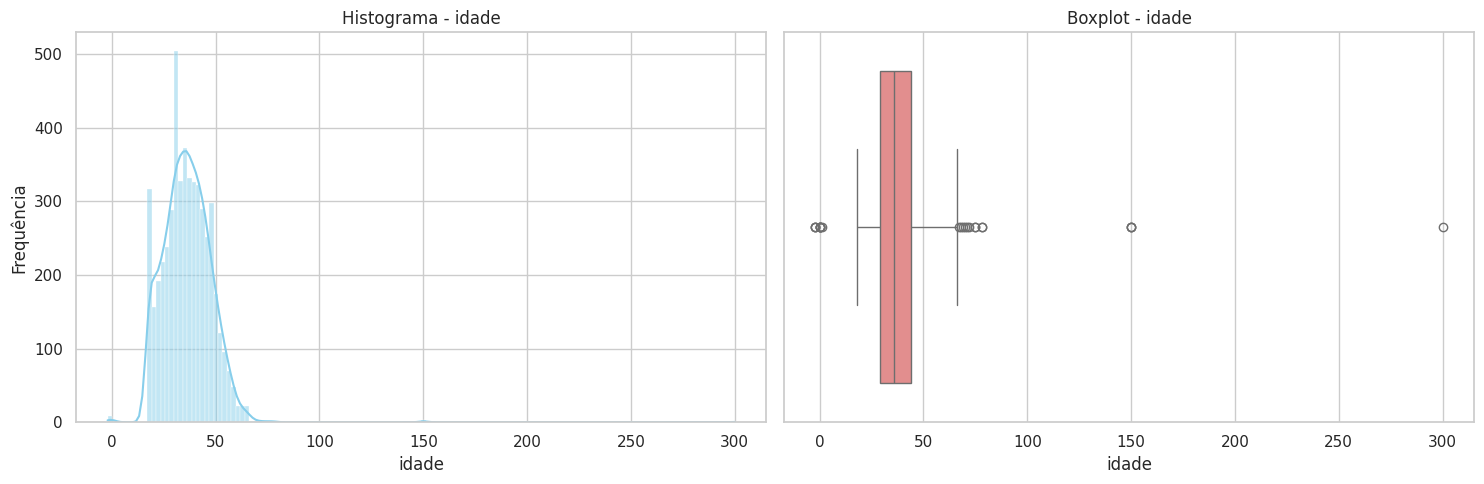

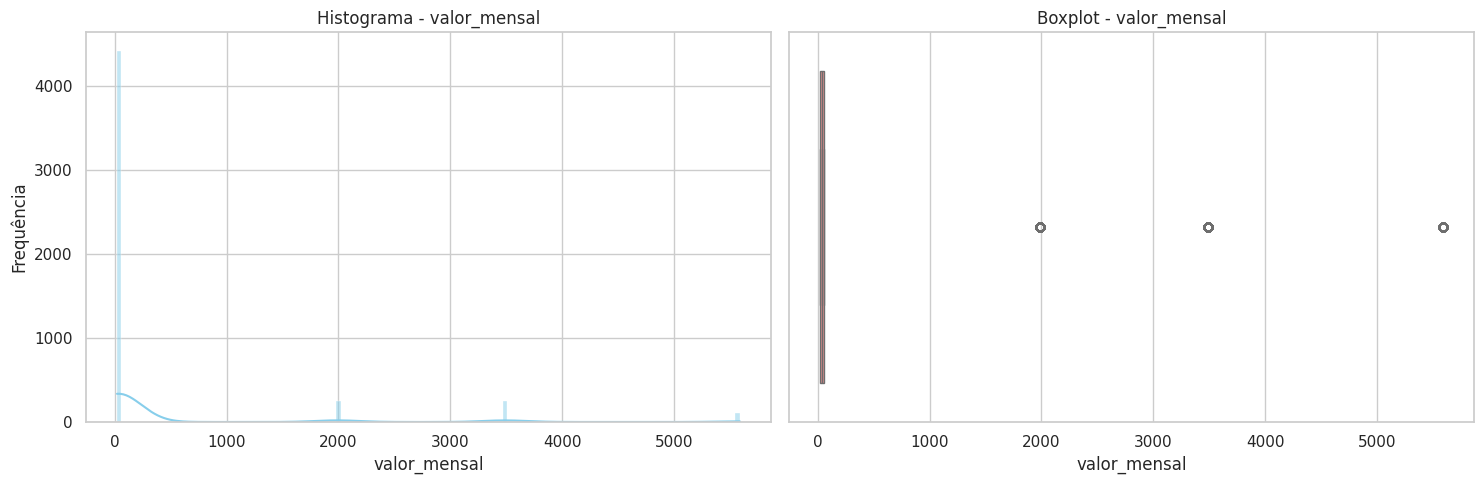

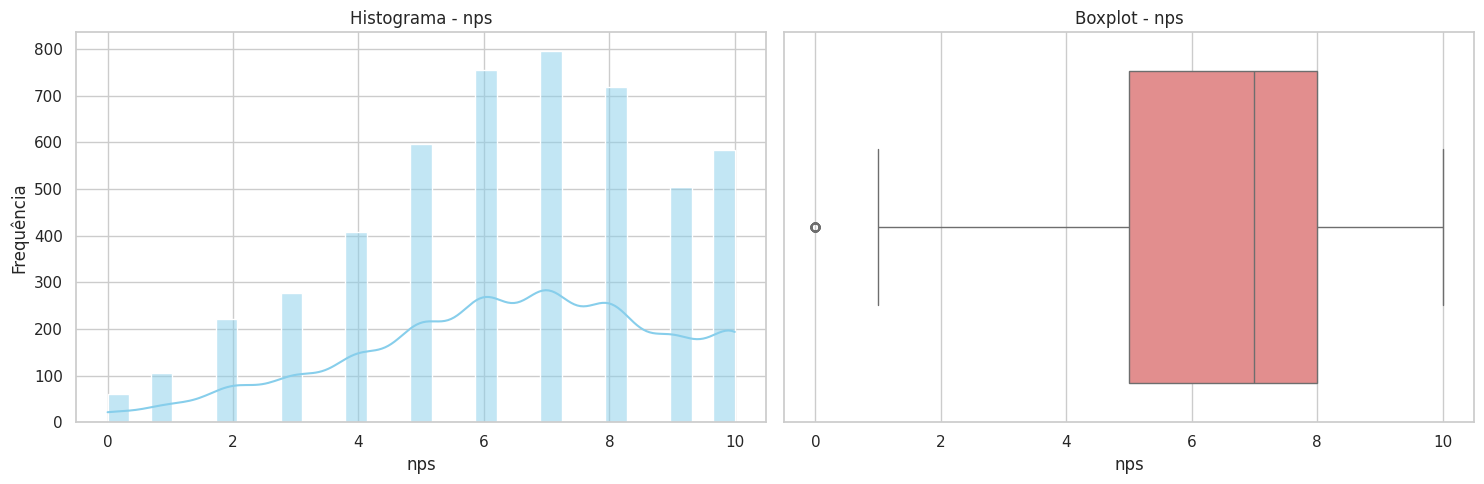

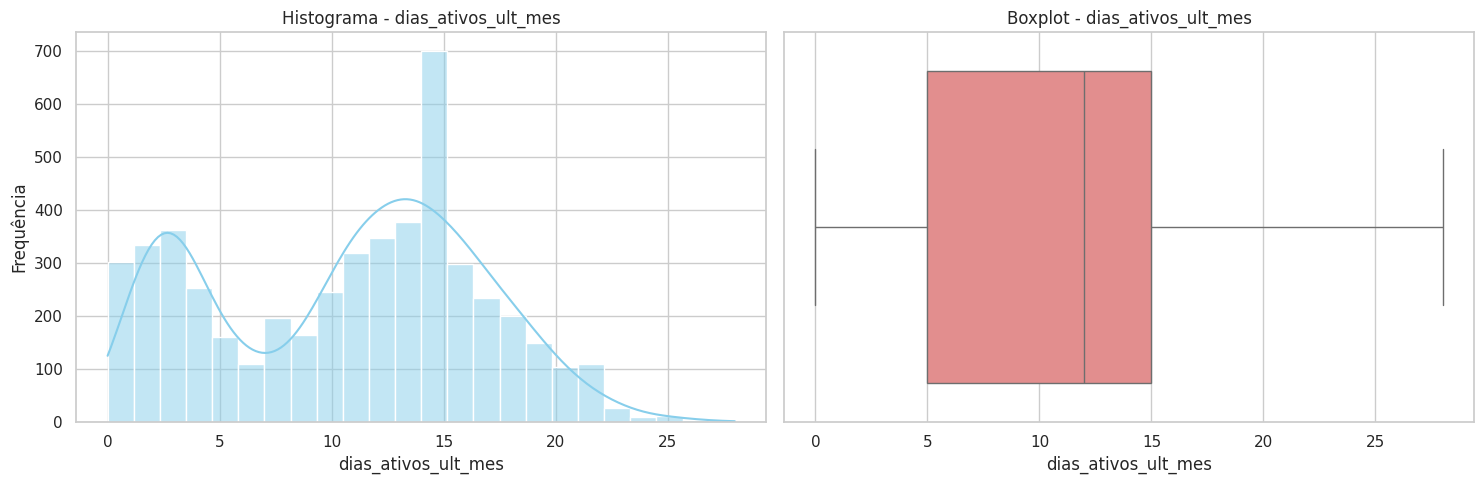

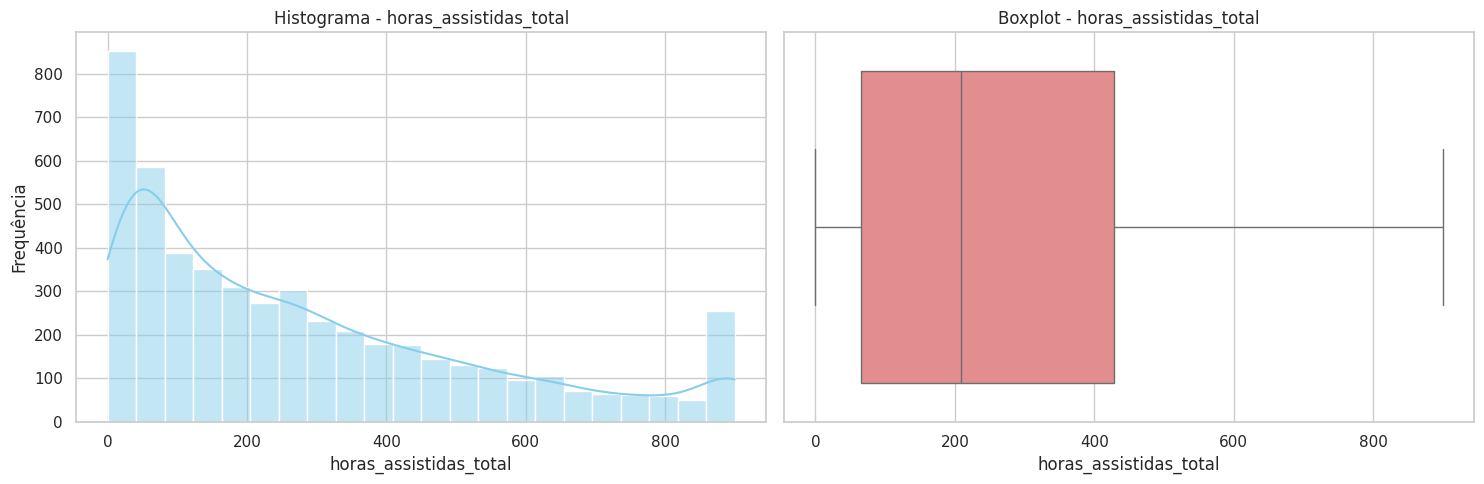

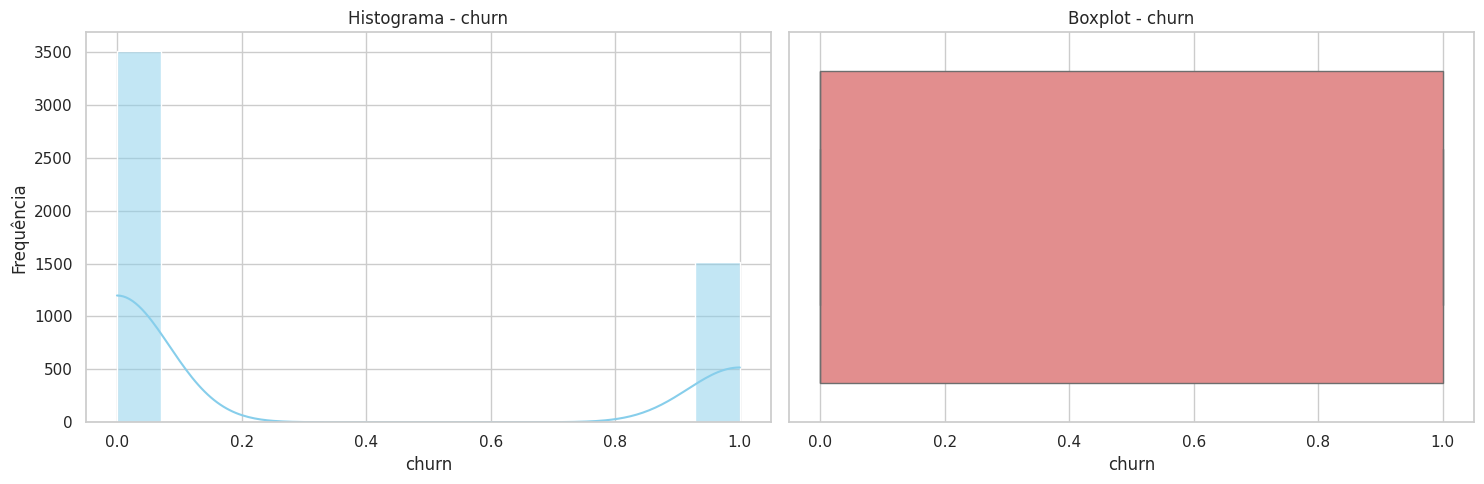

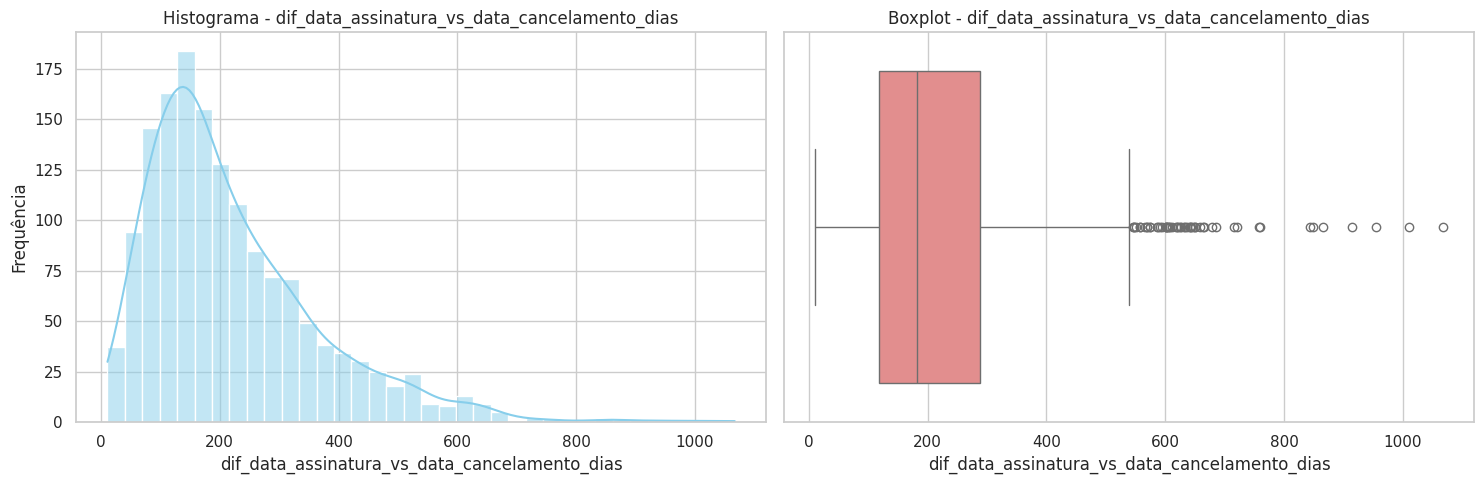

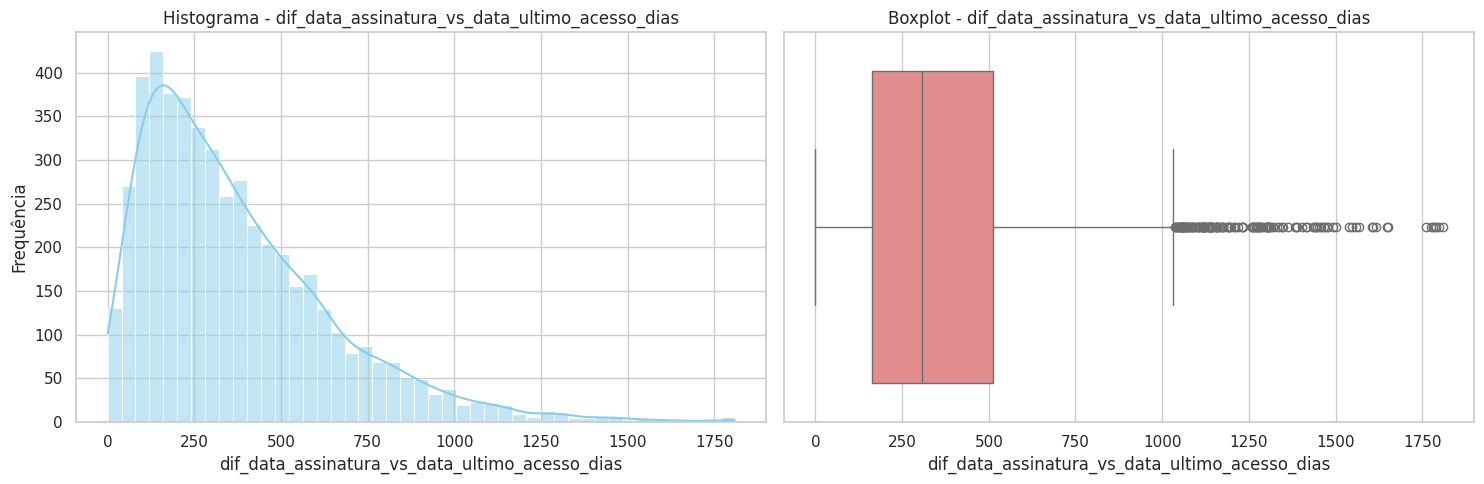

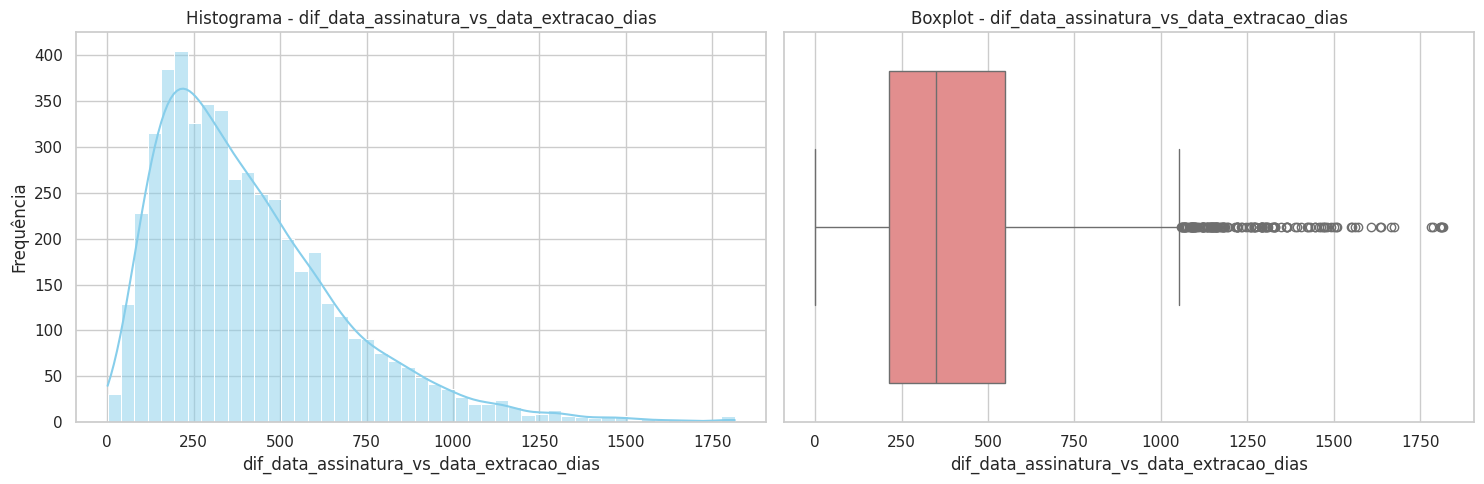

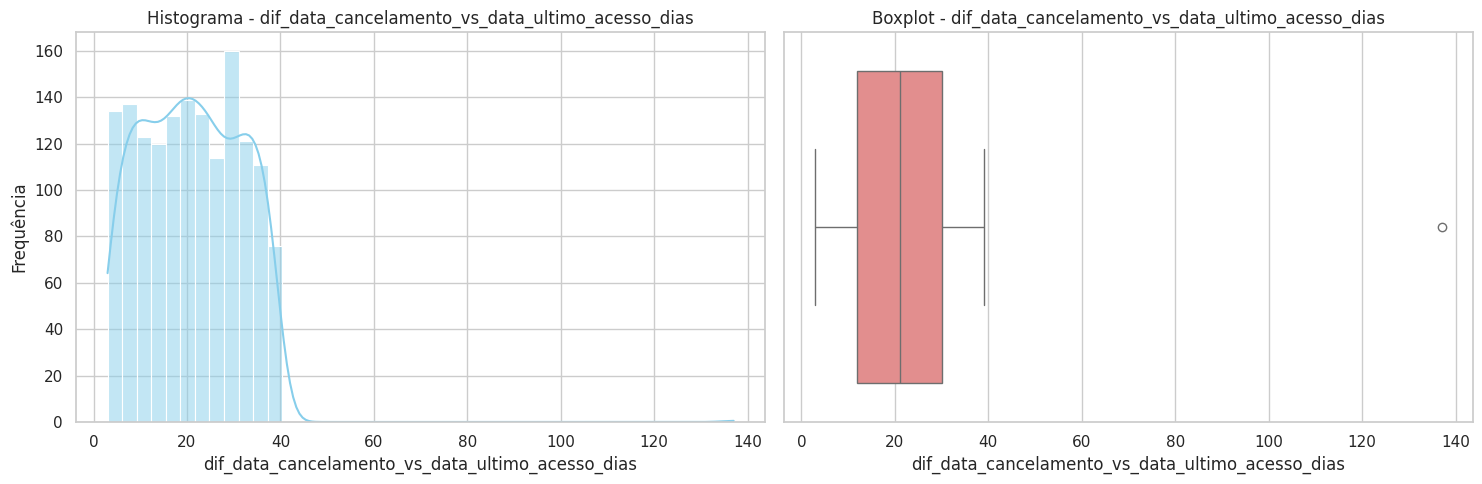

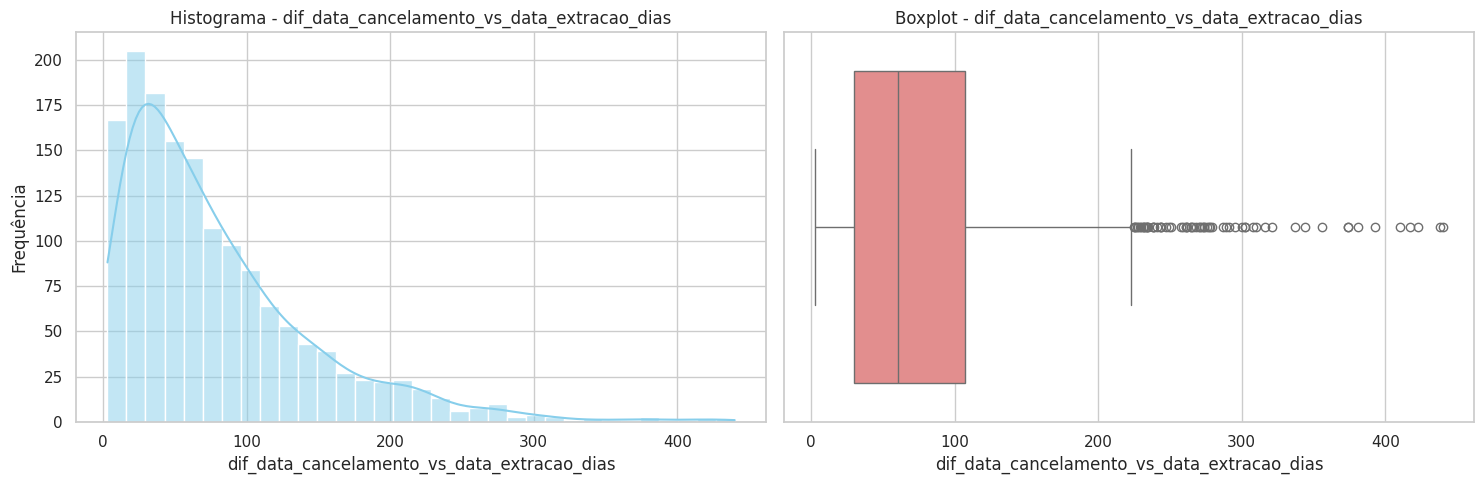

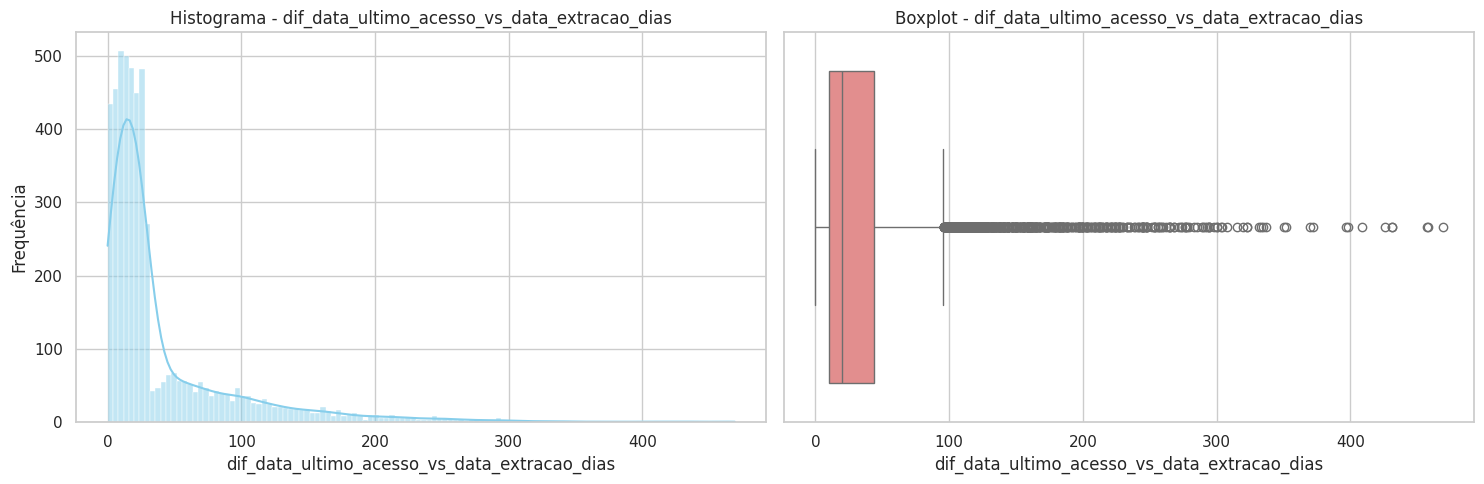

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Obter as colunas numéricas, ignorando 'cliente_id'
colunas_numericas_plot = [col for col in df_cleaned.select_dtypes(include=['number']).columns if col != 'cliente_id']

sns.set_theme(style="whitegrid")

# Loop para criar os gráficos de cada coluna numérica
for col in colunas_numericas_plot:
    # Criar uma figura com 2 subplots lado a lado (Histograma e Boxplot)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. Histograma (Lado Esquerdo)
    sns.histplot(data=df_cleaned, x=col, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma - {col}', fontsize=12)
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')

    # 2. Boxplot (Lado Direito)
    sns.boxplot(data=df_cleaned, x=col, ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot - {col}', fontsize=12)
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

In [24]:
# Armazenar a quantidade original para comparação
qtd_antes = len(df_filtered) if 'df_filtered' in locals() else len(df_cleaned)

# Filtrar mantendo apenas idades entre 18 e 90 anos (inclusive)
if 'df_filtered' in locals():
    df_filtered = df_filtered[(df_filtered['idade'] >= 18) & (df_filtered['idade'] <= 90)].copy()
else:
    df_filtered = df_cleaned[(df_cleaned['idade'] >= 18) & (df_cleaned['idade'] <= 90)].copy()

qtd_depois = len(df_filtered)

print(f"=== Remoção de Idades Inconsistentes (< 18 e > 90) ===")
print(f"Quantidade de registros antes: {qtd_antes}")
print(f"Quantidade de registros depois: {qtd_depois}")
print(f"Total de linhas removidas: {qtd_antes - qtd_depois}")

# Exibir estatísticas rápidas da idade para confirmar
display(df_filtered['idade'].describe().to_frame())

=== Remoção de Idades Inconsistentes (< 18 e > 90) ===
Quantidade de registros antes: 5025
Quantidade de registros depois: 5012
Total de linhas removidas: 13


,idade
count,5012.000000
mean,36.274741
std,10.615377
min,18.000000
25%,29.000000
50%,36.000000
75%,44.000000
max,78.000000


## Conclusões da univariada – variáveis categóricas

**1. Base suja**
- **`plano`**: "Basico" / "BASICO" / "básico" são o mesmo plano, mas contam separado (708 + 677 + 677). O mesmo com Padrão (3 formas) e Premium (2 formas). Sem unificar, você teria **8 planos** quando existem **3**.
- **`canal_aquisicao`**: pior ainda – 9 grafias para 4 canais. "Organico"/"orgânico", "Indicacao"/"indicação", "IG"/"Instagram"/"instagram", "Google"/"google".

**2. O `?` na região é ausente disfarçado** São **170 registros** com "?", que o `isnull()` não pega porque é texto. Representa ~3,4% da base sem região informada. Tratá-lo como categoria válida criaria uma "região Interrogação" nos gráficos; o certo foi convertê-lo em nulo.

**3. Insight de negócio real – a base é fortemente concentrada no Sudeste.** Somando as regiões válidas: **Sudeste (2.057) sozinho é ~42%** da base, mais que Nordeste (964) e Sul (938) juntos parciais. Norte (408) e Centro-Oeste (488) são pequenos. Isso importa para qualquer análise regional depois – há Sudeste de sobra para conclusões robustas, mas Norte tem amostra pequena, então taxa de churn dessa região terá muito mais incerteza.

**4. Insight de negócio – o produto é predominantemente mensal.** **Mensal (3.794) contra Anual (1.231)**: ~75% da base paga mês a mês.

**5. A distribuição dos canais é equilibrada – nenhum domina.** Depois de unificar: Orgânico (1.510), Instagram (1.547), Indicação (1.082), Google (886). Aquisição diversificada, sem dependência perigosa de um único canal. Saudável do ponto de vista de risco de aquisição.


# 🗺️ Guia de Análise Exploratória e Tratamento de Dados (Passo a Passo)

Este roteiro serve como um modelo lógico e prático (*pipeline*) para estruturar e executar qualquer análise univariada e limpeza de dados de ponta a ponta.

---

### 🚀 **Fase 1: Preparação e Conexão com os Dados**

1. **Conexão com a Origem:**
   * Configurar o ambiente para ler os dados (como montar o Google Drive ou conectar a um banco de dados).
   * Importar as bibliotecas essenciais para manipulação e visualização de dados:
     ```python
     import pandas as pd
     import numpy as np
     import matplotlib.pyplot as plt
     import seaborn as sns
     ```

2. **Inspeção Inicial do Dataset:**
   * Carregar o arquivo de dados (ex: utilizando `pd.read_csv`).
   * Realizar um diagnóstico rápido sobre o tamanho do conjunto de dados, tipos atribuídos às colunas e os primeiros registros:
     * `df.info()`
     * `df.dtypes`
     * `df.head()`

### 🧹 **Fase 2: Limpeza e Padronização Textual (Variáveis Categóricas)**

3. **Identificação de Redundâncias e Sujeira:**
   * Analisar os valores distintos de cada coluna categórica para identificar redundâncias decorrentes de erros de digitação, diferenças de caixa (maiúscula/minúscula) ou problemas de acentuação:
     * `df['coluna'].value_counts(dropna=False)`

4. **Normalização de Textos:**
   * Aplicar rotinas para remover espaços em branco desnecessários, padronizar letras e remover acentos gráficos.

5. **Agrupamento de Sinônimos:**
   * Unificar categorias redundantes sob o mesmo termo padrão (ex: substituir `Ig` por `Instagram`).

6. **Tratamento de Nulos Ocultos:**
   * Identificar caracteres de preenchimento que na prática representam a falta de informação (como `?` ou hifens) e convertê-los explicitamente no nulo nativo do Python (`np.nan` ou `None`).

### 📅 **Fase 3: Tratamento de Datas e Engenharia de Recursos (*Feature Engineering*)**

7. **Conversão de Tipos Temporais:**
   * Transformar colunas de datas originalmente interpretadas como texto (`object`) para o tipo nativo de data (`datetime`) usando `pd.to_datetime`.

8. **Geração de Métricas de Tempo:**
   * Calcular intervalos de dias e criar novos indicadores cruciais para o negócio a partir do cruzamento de datas importantes (como tempo de associação ou recência).

### 🔢 **Fase 4: Análise de Dados Numéricos e Tratamento de Outliers**

9. **Investigação Estatística:**
   * Executar um sumário estatístico completo das variáveis numéricas para buscar anomalias logísticas nas métricas de mínimo, máximo e média:
     * `df.describe()`

10. **Diagnóstico Visual:**
    * Plote gráficos complementares para entender a forma de distribuição dos dados:
      * **Histogramas:** Para analisar a concentração e a frequência dos valores.
      * **Boxplots:** Para mapear e sinalizar visualmente a existência de valores discrepantes (*outliers*).

11. **Saneamento e Ajustes de Regras de Negócio:**
    * Filtrar e excluir dados fisicamente inconsistentes (ex: idades abaixo do mínimo legal ou acima do limite de expectativa de vida).
    * Corrigir inconsistências de escala e padronização monetária (ex: dividir taxas anuais agrupadas por 100 para correspondência mensal).

### 📊 **Fase 5: Métricas Finais e Geração de Insights**

12. **Métricas de Performance Combinadas:**
    * Gerar indicadores consolidados de negócios cruzando variáveis puramente tratadas (ex: calcular a receita acumulada total gerada por cada cliente).

13. **Relatório de Conclusões:**
    * Documentar de forma descritiva e em tópicos os principais achados estruturais sobre a base de dados para direcionar as tomadas de decisão.

# Análise Bivariada

In [25]:
# Criar o DataFrame de análise aplicando o filtro mínimo de 220 dias
df_analise = df_filtered[df_filtered['dif_data_assinatura_vs_data_extracao_dias'] >= 220].copy()

print("=== Criação do DataFrame de Análise (Mínimo 220 dias de base) ===")
print(f"Linhas no DataFrame anterior (df_filtered): {len(df_filtered)}")
print(f"Linhas no novo DataFrame (df_analise): {len(df_analise)}")
print(f"Registros removidos: {len(df_filtered) - len(df_analise)}")

# Exibir estatísticas descritivas da coluna filtrada para confirmação
display(df_analise['dif_data_assinatura_vs_data_extracao_dias'].describe().to_frame())

=== Criação do DataFrame de Análise (Mínimo 220 dias de base) ===
Linhas no DataFrame anterior (df_filtered): 5012
Linhas no novo DataFrame (df_analise): 3668
Registros removidos: 1344


,dif_data_assinatura_vs_data_extracao_dias
count,3668.000000
mean,510.439204
std,251.757349
min,220.000000
25%,321.000000
50%,445.000000
75%,626.000000
max,1815.000000


     1. ANÁLISE DE VARIÁVEIS NUMÉRICAS VS CHURN


>>> Análise da Variável Numérica: idade <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,36.125540,36.632883
std,10.633567,10.600266
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000


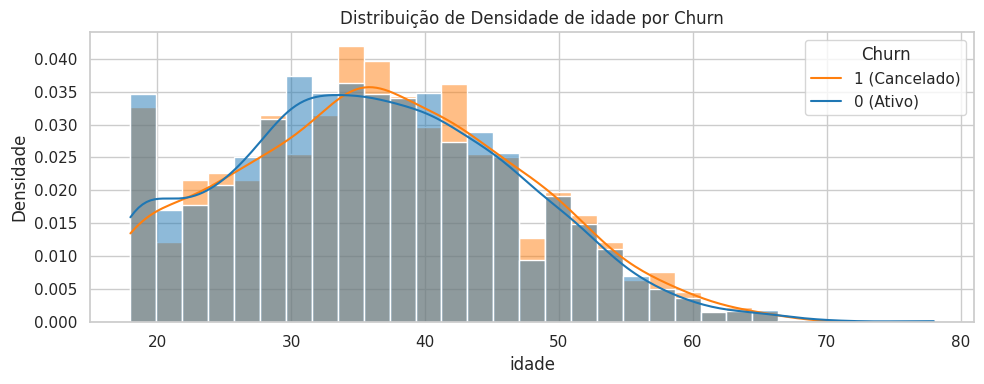


>>> Análise da Variável Numérica: valor_mensal <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,424.898597,400.209459
std,1155.321922,1079.028982
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,55.900000,55.900000
max,5590.000000,5590.000000


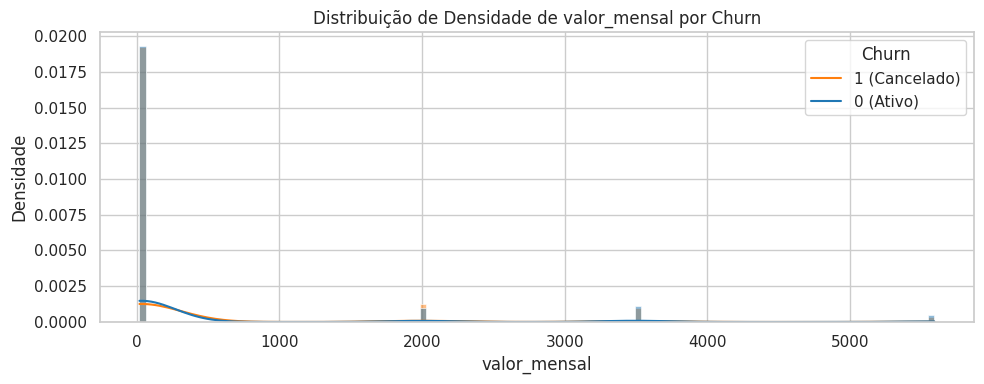


>>> Análise da Variável Numérica: nps <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,7.376978,4.090090
std,1.877014,2.004165
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000


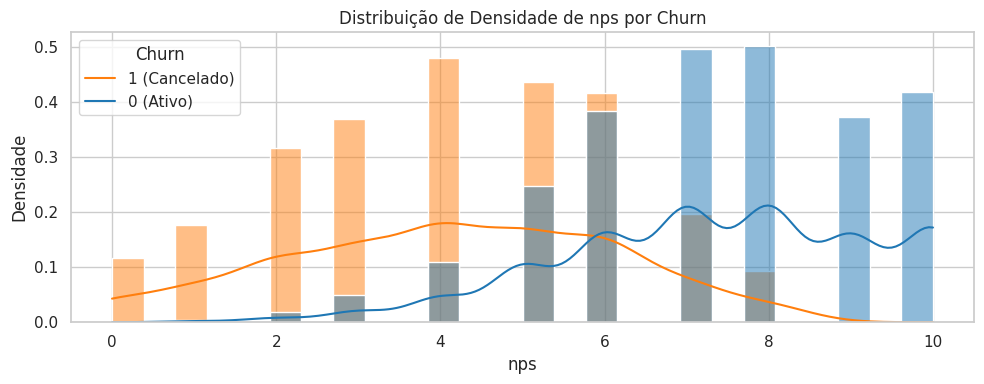


>>> Análise da Variável Numérica: dias_ativos_ult_mes <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,13.995324,2.967342
std,3.755046,1.721950
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000


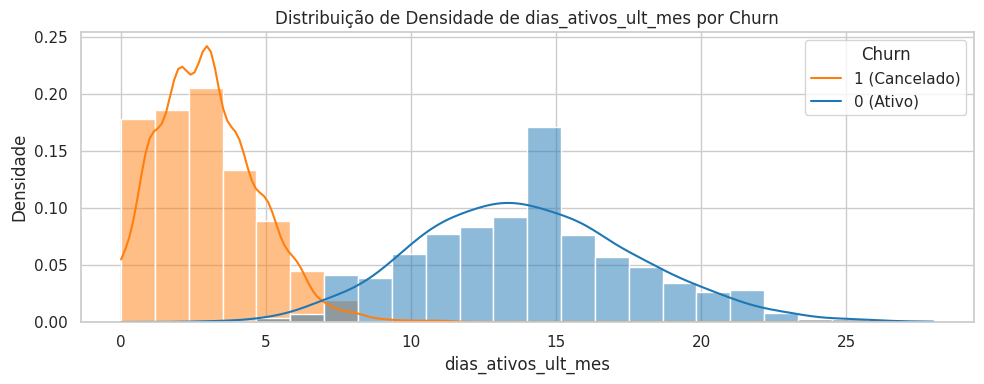


>>> Análise da Variável Numérica: horas_assistidas_total <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,448.891475,73.143131
std,226.739374,55.191559
min,73.900000,0.000000
25%,265.450000,35.925000
50%,395.600000,58.950000
75%,600.900000,96.600000
max,900.000000,400.000000


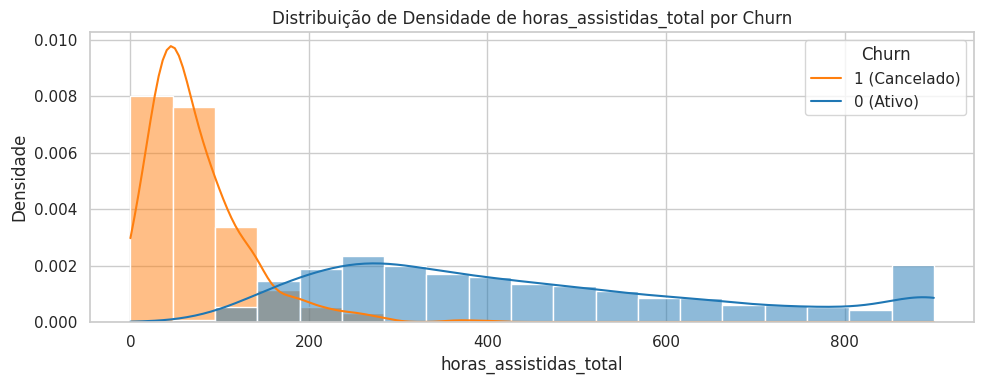


>>> Análise da Variável Numérica: dif_data_assinatura_vs_data_ultimo_acesso_dias <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2755.000000,878.000000
mean,528.301270,278.715262
std,266.179458,138.580418
min,192.000000,90.000000
25%,327.000000,176.000000
50%,465.000000,244.000000
75%,659.000000,342.500000
max,1809.000000,1040.000000


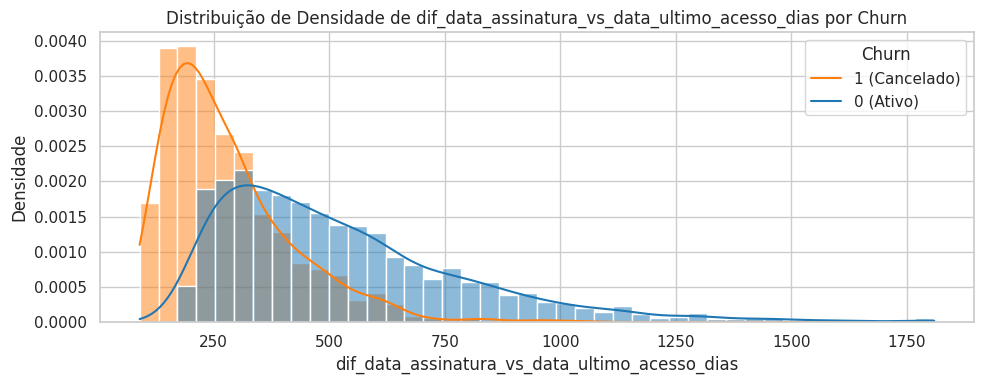


>>> Análise da Variável Numérica: dif_data_assinatura_vs_data_extracao_dias <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2780.000000,888.000000
mean,542.666187,409.548423
std,265.461831,166.733604
min,220.000000,220.000000
25%,341.000000,282.000000
50%,481.000000,364.500000
75%,673.250000,495.000000
max,1815.000000,1276.000000


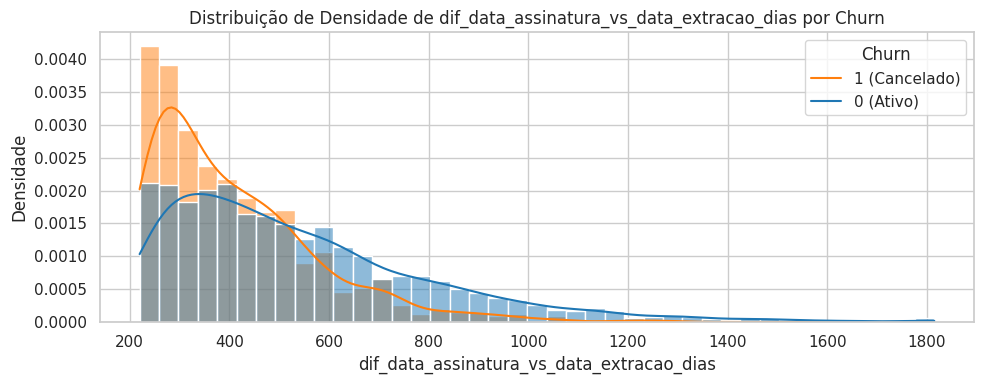


>>> Análise da Variável Numérica: dif_data_ultimo_acesso_vs_data_extracao_dias <<<


,Churn = 0 (Ativo),Churn = 1 (Cancelado)
count,2755.000000,878.000000
mean,14.603993,130.011390
std,8.493044,74.106997
min,0.000000,13.000000
25%,8.000000,75.250000
50%,14.000000,117.000000
75%,22.000000,165.000000
max,29.000000,469.000000


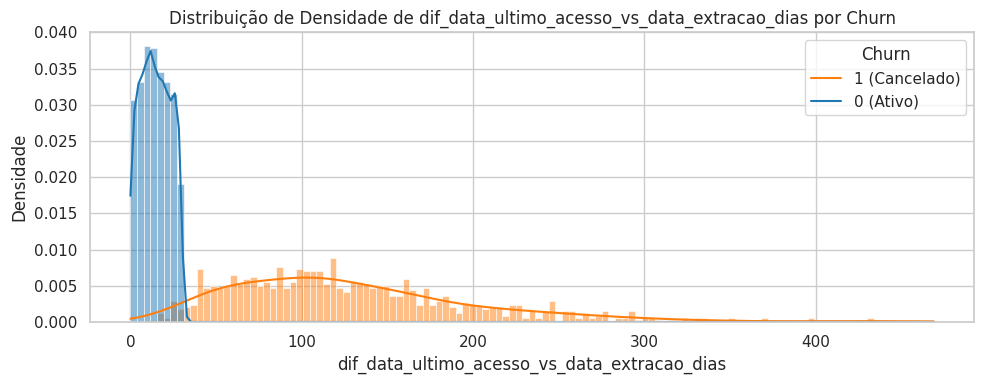


     2. ANÁLISE DE VARIÁVEIS CATEGÓRICAS VS CHURN


>>> Taxa de Churn por Categoria: plano <<<


,Total_Clientes,Quantidade_Churn,Taxa_Churn (%)
plano,,,
Basico,1486,404,27.19%
Padrao,1436,325,22.63%
Premium,746,159,21.31%



>>> Taxa de Churn por Categoria: ciclo <<<


,Total_Clientes,Quantidade_Churn,Taxa_Churn (%)
ciclo,,,
Anual,916,220,24.02%
Mensal,2752,668,24.27%



>>> Taxa de Churn por Categoria: regiao <<<


,Total_Clientes,Quantidade_Churn,Taxa_Churn (%)
regiao,,,
Centro-oeste,353,93,26.35%
Nordeste,719,172,23.92%
Norte,297,76,25.59%
Sudeste,1464,338,23.09%
Sul,707,174,24.61%



>>> Taxa de Churn por Categoria: canal_aquisicao <<<


,Total_Clientes,Quantidade_Churn,Taxa_Churn (%)
canal_aquisicao,,,
Google,635,172,27.09%
Indicacao,797,181,22.71%
Instagram,1125,280,24.89%
Organico,1111,255,22.95%


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustar layout de plots para melhor legibilidade
sns.set_theme(style="whitegrid")

# Mapeamento dos nomes de colunas numéricas de acordo com o histórico
# (Algumas colunas foram criadas na fase de tratamento de datas com nomes ligeiramente diferentes)
map_numeric = {
    'idade': 'idade',
    'valor_mensal': 'valor_mensal',
    'nps': 'nps',
    'dias_ativos_ult_mes': 'dias_ativos_ult_mes',
    'horas_assistidas_total': 'horas_assistidas_total',
    'diff_data_assinatura__data_ultimo_acesso': 'dif_data_assinatura_vs_data_ultimo_acesso_dias',
    'diff_data_assinatura__data_extracao': 'dif_data_assinatura_vs_data_extracao_dias',
    'recencia': 'dif_data_ultimo_acesso_vs_data_extracao_dias', # Usado como proxy para recência no histórico
    'meses_assinatura': 'dif_data_assinatura_vs_data_ultimo_acesso_dias', # Proxy de tempo ativo
    'receita_acumulada': 'receita_acumulada'
}

# Filtrar apenas as variáveis numéricas que de fato existem na base
vars_numericas = []
for k, v in map_numeric.items():
    if v in df_analise.columns and v not in vars_numericas:
        vars_numericas.append(v)

vars_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

print("===========================================================")
print("     1. ANÁLISE DE VARIÁVEIS NUMÉRICAS VS CHURN")
print("===========================================================\n")

for col in vars_numericas:
    print(f"\n>>> Análise da Variável Numérica: {col} <<<")

    # 1. Tabela de estatísticas por grupo de churn
    estatisticas = df_analise.groupby('churn')[col].describe().T
    # Ajustar labels para melhor clareza
    estatisticas.columns = ['Churn = 0 (Ativo)', 'Churn = 1 (Cancelado)']
    display(estatisticas)

    # 2. Histograma de densidade sobreposto
    plt.figure(figsize=(10, 4))
    sns.histplot(
        data=df_analise,
        x=col,
        hue='churn',
        kde=True,
        stat="density",
        common_norm=False,
        palette={0: "#1f77b4", 1: "#ff7f0e"},
        alpha=0.5
    )
    plt.title(f'Distribuição de Densidade de {col} por Churn', fontsize=12)
    plt.xlabel(col)
    plt.ylabel('Densidade')
    plt.legend(title='Churn', labels=['1 (Cancelado)', '0 (Ativo)'])
    plt.tight_layout()
    plt.show()

print("\n===========================================================")
print("     2. ANÁLISE DE VARIÁVEIS CATEGÓRICAS VS CHURN")
print("===========================================================\n")

for col in vars_categoricas:
    if col in df_analise.columns:
        print(f"\n>>> Taxa de Churn por Categoria: {col} <<<")

        # Tabela de contingência com taxas de churn em porcentagem
        tabela_churn = df_analise.groupby(col)['churn'].agg(
            Total_Clientes='count',
            Quantidade_Churn='sum',
            Taxa_Churn=lambda x: (x.sum() / x.count()) * 100
        ).round(2)

        # Formatar a taxa de Churn para exibição em %
        tabela_churn['Taxa_Churn (%)'] = tabela_churn['Taxa_Churn'].astype(str) + '%'
        tabela_churn = tabela_churn.drop(columns=['Taxa_Churn'])

        display(tabela_churn)


In [27]:
# Definindo a lista de colunas numéricas com base nas variáveis existentes no seu df_analise
numerical_cols = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes',
    'horas_assistidas_total', 'dif_data_assinatura_vs_data_ultimo_acesso_dias',
    'dif_data_assinatura_vs_data_extracao_dias', 'dif_data_ultimo_acesso_vs_data_extracao_dias',
    'receita_acumulada'
]

print("Estatísticas Descritivas para Variáveis Numéricas por Churn (Média, Desvio Padrão, Quartis, etc.):\n")
for col in numerical_cols:
    if col in df_analise.columns:
        print(f"--- {col} ---")
        # Exibindo o sumário estatístico completo
        display(df_analise.groupby('churn')[col].describe())
        print("\n")

Estatísticas Descritivas para Variáveis Numéricas por Churn (Média, Desvio Padrão, Quartis, etc.):

--- idade ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,36.125540,10.633567,18.0,29.0,36.0,44.0,78.0
1,888.0,36.632883,10.600266,18.0,29.0,36.0,44.0,66.0




--- valor_mensal ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,424.898597,1155.321922,19.9,19.9,34.9,55.9,5590.0
1,888.0,400.209459,1079.028982,19.9,19.9,34.9,55.9,5590.0




--- nps ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,7.376978,1.877014,1.0,6.0,7.0,9.0,10.0
1,888.0,4.090090,2.004165,0.0,3.0,4.0,6.0,8.0


... (6 outputs left out)



--- dif_data_assinatura_vs_data_extracao_dias ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,542.666187,265.461831,220.0,341.0,481.0,673.25,1815.0
1,888.0,409.548423,166.733604,220.0,282.0,364.5,495.00,1276.0




--- dif_data_ultimo_acesso_vs_data_extracao_dias ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,14.603993,8.493044,0.0,8.00,14.0,22.0,29.0
1,878.0,130.011390,74.106997,13.0,75.25,117.0,165.0,469.0


## 📊 Segmentação RFM Adaptada para Streaming

Nesta seção, adaptamos o modelo RFM tradicional para o comportamento de consumo em streaming de nossos clientes **ativos** (`churn == 0`):
* **Recência (R):** Dias desde o último acesso (`dif_data_ultimo_acesso_vs_data_extracao_dias`). Menores valores indicam maior proximidade (melhor).
* **Frequência (F):** Dias ativos no último mês (`dias_ativos_ult_mes`). Maiores valores indicam uso frequente (melhor).
* **Monetário (M):** Valor da mensalidade (`valor_mensal`). Maiores valores indicam planos mais caros (melhor).

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar apenas clientes ativos (churn == 0)
df_rfm_raw = df_filtered[df_filtered['churn'] == 0].copy()

# Garantir coluna amigável 'recencia'
if 'recencia' not in df_rfm_raw.columns:
    df_rfm_raw['recencia'] = df_rfm_raw['dif_data_ultimo_acesso_vs_data_extracao_dias']

# Passo 1: Remover linhas onde a recência é nula
df_rfm = df_rfm_raw.dropna(subset=['recencia']).copy()

print(f"Clientes ativos originais: {len(df_rfm_raw)}")
print(f"Clientes ativos após remover nulos de recência: {len(df_rfm)}\n")

# Passo 2: Atribuição de notas de 1 a 5 usando rank percentual (evita erro de limites duplicados)
# Recência: Menor é melhor -> Menor recência ganha nota 5. Usamos o método 'first' para garantir distribuição uniforme e sem empates nos bins.
rec_pct = df_rfm['recencia'].rank(pct=True, method='first')
df_rfm['R'] = pd.cut(rec_pct, bins=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[5, 4, 3, 2, 1], include_lowest=True).astype(int)

# Frequência: Maior é melhor -> Maior frequência ganha nota 5.
freq_pct = df_rfm['dias_ativos_ult_mes'].rank(pct=True, method='first')
df_rfm['F'] = pd.cut(freq_pct, bins=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Monetário: Maior é melhor -> Maior valor mensal ganha nota 5.
mon_pct = df_rfm['valor_mensal'].rank(pct=True, method='first')
df_rfm['M'] = pd.cut(mon_pct, bins=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Mostrar os intervalos reais aproximados por trás de cada nota (apenas para exibição)
print("=== Intervalos Reais Aproximados de Cada Nota (Quintis Verdadeiros) ===")
print("Recência:")
print(pd.qcut(df_rfm['recencia'], q=5, duplicates='drop').value_counts().sort_index())
print("\nFrequência:")
print(pd.qcut(df_rfm['dias_ativos_ult_mes'], q=5, duplicates='drop').value_counts().sort_index())
print("\nMonetário:")
print(pd.qcut(df_rfm['valor_mensal'], q=5, duplicates='drop').value_counts().sort_index())


Clientes ativos originais: 3500
Clientes ativos após remover nulos de recência: 3465

=== Intervalos Reais Aproximados de Cada Nota (Quintis Verdadeiros) ===
Recência:
recencia
(-0.001, 6.0]    790
(6.0, 11.0]      601
(11.0, 17.0]     705
(17.0, 23.0]     682
(23.0, 29.0]     687
Name: count, dtype: int64

Frequência:
dias_ativos_ult_mes
(2.999, 11.0]    922
(11.0, 13.0]     711
(13.0, 15.0]     694
(15.0, 17.0]     527
(17.0, 28.0]     611
Name: count, dtype: int64

Monetário:
valor_mensal
(19.898999999999997, 34.9]    2416
(34.9, 55.9]                   642
(55.9, 5590.0]                 407
Name: count, dtype: int64


=== Distribuição e Volumetria dos Segmentos RFM ===


,Contagem,Porcentagem
Segmento,,
Regulares,967,27.91%
Em risco,826,23.84%
Engajados,566,16.33%
Adormecidos,560,16.16%
Novos/Ativos recentes,546,15.76%


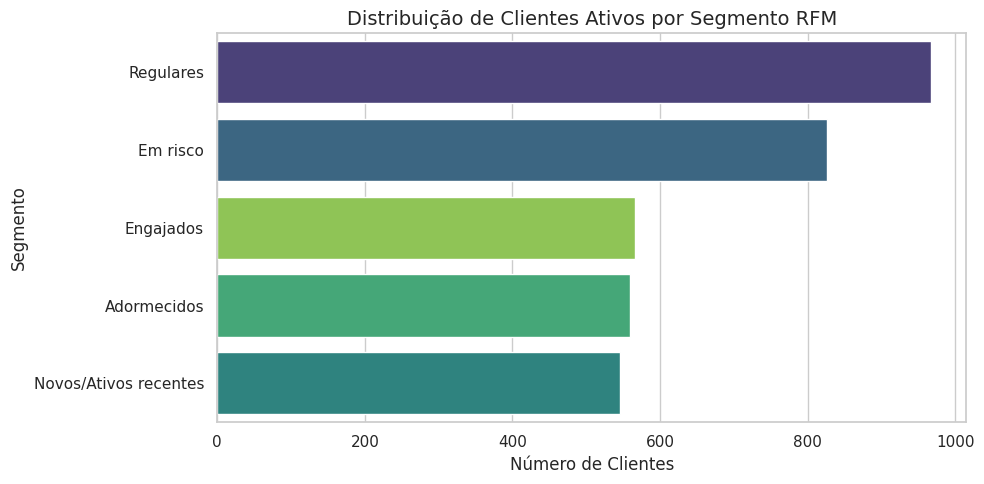

In [40]:
# Passo 3: Criar a coluna com o código RFM consolidado
df_rfm['RFM_codigo'] = 'R' + df_rfm['R'].astype(str) + 'F' + df_rfm['F'].astype(str) + 'M' + df_rfm['M'].astype(str)

# Passo 4: Classificação de cada cliente em segmentos claros
def definir_segmento(row):
    r = row['R']
    f = row['F']
    if r >= 4 and f >= 4:
        return "Engajados"
    elif r <= 2 and f >= 3:
        return "Em risco"
    elif r >= 4 and f <= 2:
        return "Novos/Ativos recentes"
    elif r <= 2 and f <= 2:
        return "Adormecidos"
    else:
        return "Regulares"

df_rfm['Segmento'] = df_rfm.apply(definir_segmento, axis=1)

# Passo 5: Exibir estatísticas (contagem e porcentagem)
stats_segmento = df_rfm['Segmento'].value_counts().to_frame(name='Contagem')
stats_segmento['Porcentagem'] = ((stats_segmento['Contagem'] / stats_segmento['Contagem'].sum()) * 100).round(2).astype(str) + '%'

print("=== Distribuição e Volumetria dos Segmentos RFM ===")
display(stats_segmento)

# Plotagem do gráfico de barras horizontais
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_rfm,
    y='Segmento',
    order=stats_segmento.index,
    hue='Segmento',
    palette='viridis',
    legend=False
)
plt.title('Distribuição de Clientes Ativos por Segmento RFM', fontsize=14)
plt.xlabel('Número de Clientes')
plt.ylabel('Segmento')
plt.tight_layout()
plt.show()


## Cuidados importantes com conclusões precipitadas

**dias_ativos_ult_mes** — Quem já deu churn não teve acesso nos últimos meses, então aparece zerado por definição — não porque usava pouco, mas porque já tinha saído.

**data_ultimo_acesso (e a recência derivada dela)** — Mesma contaminação. Para quem cancelou, o último acesso trava perto da data de saída, então a recência reflete o churn que já aconteceu, não um comportamento que o antecede. *Serve para descrever engajamento entre ativos, mas como preditor de churn é enganosa*

**horas_assistidas_total** — Viés parcial em 2 frentes. Primeiro, quem deu churn parou de assistir antes de sair, então *acumula menos horas naturalmente*, não é uma CAUSA do churn prévio. Segundo, é confundida pelo *tempo de casa*: veterano naturalmente acumula mais horas — legal ser normalizada por `meses_assinatura` para comparar de forma justa

**meses_assinatura** — entre os clientes maduros, quem permanece ativo tem mais tempo de casa acumulado do que quem cancelou, o que é esperado — cliente que não dá churn continua na base acumulando meses, enquanto o do churner congela no cancelamento. A leitura honesta é descritiva: os sobreviventes são, por natureza, mais antigos, e há um sinal real de que quem cancela tende a durar menos. Vale só a ressalva de não transformar isso diretamente numa regra preditiva ("abaixo de X meses = risco"), porque o tempo do churner está fechado e o do ativo ainda corre — a forma rigorosa de medir essa queda de permanência ao longo do tempo é a análise de cohort, que desdobra essa diferença agregada na curva de retenção mês a mês.

**tempo até o churn (data_cancelamento – data_assinatura)** — Só existe para quem deu churn (cancelamento é vazio nos ativos). Não entra em comparação churn vs não-churn; serve para *entender* quando o churn acontece — foi daí que [...]

**tempo desde o último acesso até o cancelamento (data_cancelamento – data_ultimo_acesso)** — Também exclusiva de quem cancelou. Descreve o comportamento de saída, não entra em comparação churn vs não-churn

**Qualquer diferença que envolva `data_ultimo_acesso` ou `data_cancelamento` carrega o churn dentro dela**, porque essas duas datas são marcadas pelo próprio desfecho.

As diferenças "limpas" para entender padrão churn x não churn são as que dependem só de `data_assinatura` e `data_extracao` (a maturidade) — e mesmo essa exige o corte para não enganar.

## Conclusões análise bivariada

Aqui estão os insights só da bivariada, com os números do notebook (recorte maduro, ≥220 dias):

**Premissa:** análise feita sobre clientes com pelo menos 220 dias de assinatura — o recorte que garante que a pessoa teve tempo real de dar churn.

**1. NPS é o sinal mais forte** E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

**2. Idade e valor do plano praticamente não separam.** Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequência do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

**3. Ciclo e região.** Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo — o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

**4. Canal de aquisição tem efeito leve, mas com valor de negócio.** Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele — canais diferentes trazem clientes com propensões diferentes.

**5. As variáveis de engajamento PARECEM separar espetacularmente — armadilha.** Dias ativos (14 vs 3), horas assistidas (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são **contaminadas por vazamento de target**: a pessoa parou de usar *porque* saiu, não o contrário (*churn causa a variável, não o contrário*). A separação é quase circular — elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.

```markdown
## 🎯 Framework 3 — Pareto dos Motivos de Cancelamento

Nesta seção, realizamos uma análise de Pareto sobre os motivos que levaram ao cancelamento dos clientes (`churn == 1`). O objetivo é identificar a minoria de causas que geram a maioria dos problemas (regra 80/20), permitindo priorizar as ações de retenção.
```

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Usar df_filtered conforme solicitado (evitando o viés de corte de 220 dias para ver a totalidade dos motivos)
df_pareto_raw = df_filtered[df_filtered['churn'] == 1].copy()

# 1. Função de normalização textual
def normalizar_motivo(texto):
    if pd.isna(texto):
        return np.nan
    texto = str(texto).strip().lower()
    # Dicionário de remoção de acentos mais comuns
    substituicoes = {
        'á': 'a', 'ã': 'a', 'â': 'a', 'à': 'a',
        'é': 'e', 'ê': 'e',
        'í': 'i',
        'ó': 'o', 'õ': 'o', 'ô': 'o',
        'ú': 'u',
        'ç': 'c'
    }
    for k, v in substituicoes.items():
        texto = texto.replace(k, v)
    return texto

# Normalizar a coluna de motivos
df_pareto_raw['motivo_cancelamento_limpo'] = df_pareto_raw['motivo_cancelamento'].apply(normalizar_motivo)

# Ignorar nulos para a análise de Pareto
df_motivos = df_pareto_raw.dropna(subset=['motivo_cancelamento_limpo']).copy()

# 2. Construir tabela de frequências (Pareto)
tabela_pareto = df_motivos['motivo_cancelamento_limpo'].value_counts().reset_index()
tabela_pareto.columns = ['Motivo', 'Quantidade']

total_cancelamentos = tabela_pareto['Quantidade'].sum()
tabela_pareto['Porcentagem (%)'] = (tabela_pareto['Quantidade'] / total_cancelamentos) * 100
tabela_pareto['Porcentagem Acumulada (%)'] = tabela_pareto['Porcentagem (%)'].cumsum()

print("=== Tabela de Pareto de Motivos de Cancelamento ===")
display(tabela_pareto.style.format({
    'Porcentagem (%)': '{:.2f}%',
    'Porcentagem Acumulada (%)': '{:.2f}%'
}))

# 3. Identificar os principais motivos que somam cerca de 80% dos casos
motivos_80 = tabela_pareto[tabela_pareto['Porcentagem Acumulada (%)'] - tabela_pareto['Porcentagem (%)'] < 80]
print("\n=== Motivos que concentram cerca de 80% dos cancelamentos ===")
for idx, row in motivos_80.iterrows():
    print(f"- {row['Motivo'].capitalize()} ({row['Quantidade']} cancelamentos | {row['Porcentagem (%)']:.2f}% do total)")

=== Tabela de Pareto de Motivos de Cancelamento ===


,Motivo,Quantidade,Porcentagem (%),Porcentagem Acumulada (%)
0,preco,508,33.60%,33.60%
1,pouco conteudo novo,384,25.40%,58.99%
2,problema tecnico,249,16.47%,75.46%
3,falta de tempo,174,11.51%,86.97%
4,concorrente,130,8.60%,95.57%
5,outro,67,4.43%,100.00%



=== Motivos que concentram cerca de 80% dos cancelamentos ===
- Preco (508 cancelamentos | 33.60% do total)
- Pouco conteudo novo (384 cancelamentos | 25.40% do total)
- Problema tecnico (249 cancelamentos | 16.47% do total)
- Falta de tempo (174 cancelamentos | 11.51% do total)


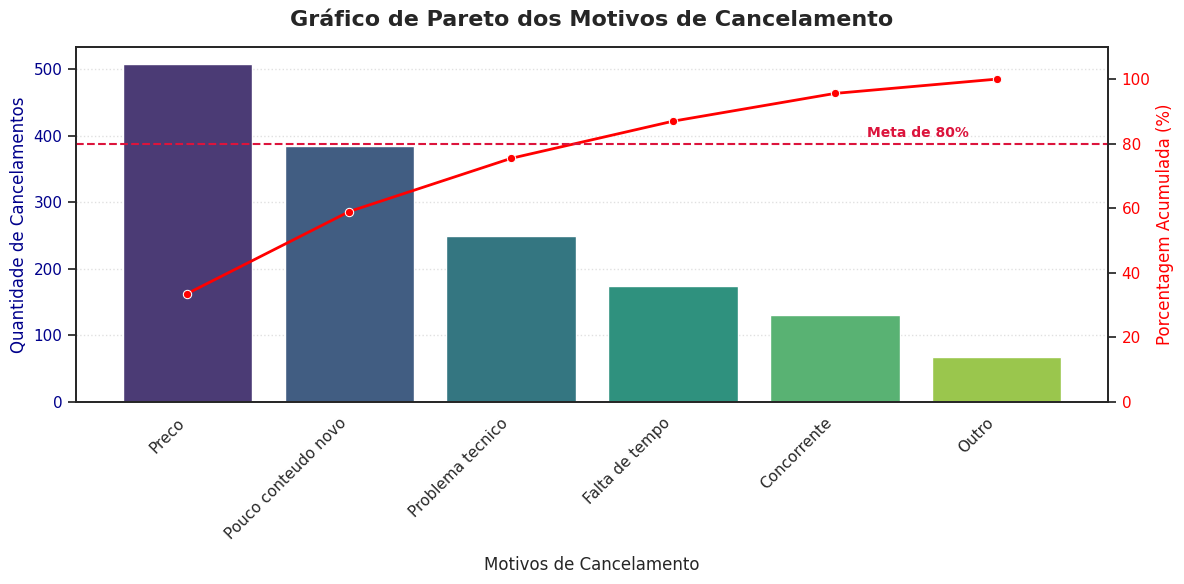

In [43]:
# 4. Gráfico de Pareto
sns.set_theme(style="white")

fig, ax1 = plt.subplots(figsize=(12, 6))

# Gráfico de Barras (Quantidade) - Eixo Esquerdo
sns.barplot(
    data=tabela_pareto,
    x='Motivo',
    y='Quantidade',
    ax=ax1,
    palette='viridis',
    hue='Motivo',
    legend=False
)
ax1.set_title('Gráfico de Pareto dos Motivos de Cancelamento', fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('Motivos de Cancelamento', fontsize=12, labelpad=10)
ax1.set_ylabel('Quantidade de Cancelamentos', fontsize=12, color='darkblue')
ax1.tick_params(axis='y', labelcolor='darkblue')

# Fixar ticks explicitamente antes de definir as labels para evitar o UserWarning
ax1.set_xticks(range(len(tabela_pareto)))
ax1.set_xticklabels(tabela_pareto['Motivo'].str.capitalize(), rotation=45, ha='right')

# Gráfico de Linha (Porcentagem Acumulada) - Eixo Direito
ax2 = ax1.twinx()
sns.lineplot(
    data=tabela_pareto,
    x='Motivo',
    y='Porcentagem Acumulada (%)',
    ax=ax2,
    color='red',
    marker='o',
    sort=False,
    linewidth=2
)
ax2.set_ylabel('Porcentagem Acumulada (%)', fontsize=12, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 110)

# Linha horizontal de referência em 80%
ax2.axhline(80, color='crimson', linestyle='--', linewidth=1.5, label='Linha de 80%')
ax2.text(len(tabela_pareto)-1.8, 82, 'Meta de 80%', color='crimson', fontweight='bold', fontsize=10)

# Adicionar grid para facilitar visualização
ax1.grid(True, axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

```markdown
## 🏁 Framework 4 — Funil de Onboarding

Nesta seção, analisamos o comportamento do usuário durante a jornada de boas-vindas (*onboarding*) utilizando o histórico contido no arquivo `funil_eventos.csv` para mapear taxas de conversão entre etapas e gargalos do produto.
```

In [44]:
import os
import pandas as pd

def localizar_e_carregar_funil():
    print("Buscando o arquivo 'funil_eventos.csv' no Google Drive dinamicamente...")
    caminho_encontrado = None

    for raiz, diretorios, arquivos in os.walk('/content/drive'):
        if 'funil_eventos.csv' in arquivos:
            caminho_encontrado = os.path.join(raiz, 'funil_eventos.csv')
            break

    if caminho_encontrado:
        print(f"Arquivo localizado com sucesso em: {caminho_encontrado}")
        df_temp = pd.read_csv(caminho_encontrado)
        return df_temp
    else:
        raise FileNotFoundError("Não foi possível localizar o arquivo 'funil_eventos.csv' no seu Google Drive.")

try:
    # Carregar o DataFrame
    df_funil = localizar_e_carregar_funil()

    # Guardar tamanho original
    tam_original = len(df_funil)

    # Remover linhas duplicadas
    df_funil = df_funil.drop_duplicates()
    tam_final = len(df_funil)

    print(f"\nRegistros originais: {tam_original}")
    print(f"Registros após remover duplicadas: {tam_final}")
    print(f"Duplicadas removidas: {tam_original - tam_final}")

    # Exibir primeiras linhas
    print("\n--- Prévia do DataFrame do Funil ---")
    display(df_funil.head())

    # Exibir resumo de informações
    print("\n--- Resumo de Informações ---")
    display(df_funil.info())
except Exception as e:
    print(f"Erro ao processar: {e}")

Buscando o arquivo 'funil_eventos.csv' no Google Drive dinamicamente...
Arquivo localizado com sucesso em: /content/drive/MyDrive/UNIPDS/Business_Analytics/Estatística/funil_eventos.csv

Registros originais: 12886
Registros após remover duplicadas: 12836
Duplicadas removidas: 50

--- Prévia do DataFrame do Funil ---


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula



--- Resumo de Informações ---
<class 'pandas.core.frame.DataFrame'>
Index: 12836 entries, 0 to 12885
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   cliente_id  12836 non-null  int64 
 1   etapa       12836 non-null  object
dtypes: int64(1), object(1)
memory usage: 300.8+ KB


None

In [45]:
import pandas as pd

# 1. Identificar as etapas exclusivas presentes no arquivo para garantir o mapeamento correto
etapas_unicas = df_funil['etapa'].unique()
print("Etapas detectadas no dataset:", etapas_unicas)

# 2. Definir a ordem lógica sequencial do funil de onboarding/conversão
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou plano', 'renovou']

# 3. Contar clientes únicos por etapa
dados_funil = []
for etapa in ordem_funil:
    if etapa in df_funil['etapa'].values:
        qtd_usuarios = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
        dados_funil.append({'Etapa': etapa, 'Usuarios': qtd_usuarios})

df_metricas_funil = pd.DataFrame(dados_funil)

# 4. Calcular taxas de conversão
topo_funil_usuarios = df_metricas_funil.iloc[0]['Usuarios']
df_metricas_funil['Conversao_Absoluta (%)'] = (df_metricas_funil['Usuarios'] / topo_funil_usuarios) * 100

conversao_incremental = [100.0]
for i in range(1, len(df_metricas_funil)):
    anterior = df_metricas_funil.iloc[i-1]['Usuarios']
    atual = df_metricas_funil.iloc[i]['Usuarios']
    taxa = (atual / anterior) * 100
    conversao_incremental.append(taxa)

df_metricas_funil['Conversao_Incremental (%)'] = conversao_incremental

print("\n=== Métricas de Conversão do Funil de Onboarding ===")
display(df_metricas_funil.style.format({
    'Conversao_Absoluta (%)': '{:.2f}%',
    'Conversao_Incremental (%)': '{:.2f}%'
}))

Etapas detectadas no dataset: ['assistiu_1a_aula' 'criou_conta' 'visitou_site' 'renovou' 'assinou plano'
 'assinou_plano' 'Assinou_Plano']

=== Métricas de Conversão do Funil de Onboarding ===


,Etapa,Usuarios,Conversao_Absoluta (%),Conversao_Incremental (%)
0,visitou_site,5000,100.00%,100.00%
1,criou_conta,3377,67.54%,67.54%
2,assistiu_1a_aula,2698,53.96%,79.89%
3,assinou plano,349,6.98%,12.94%
4,renovou,695,13.90%,199.14%


In [46]:
import pandas as pd

# 1. Identificar as etapas exclusivas presentes no arquivo para garantir o mapeamento correto
etapas_unicas = df_funil['etapa'].unique()
print("Etapas detectadas no dataset:", etapas_unicas)

# 2. Definir a ordem lógica sequencial do funil de onboarding/conversão
# Ordem sugerida: visitou_site -> criou_conta -> assistiu_1a_aula -> assinou plano -> renovou
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou plano', 'renovou']

# 3. Contar clientes únicos por etapa
dados_funil = []
for etapa in ordem_funil:
    if etapa in df_funil['etapa'].values:
        qtd_usuarios = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
        dados_funil.append({'Etapa': etapa, 'Usuarios': qtd_usuarios})

df_metricas_funil = pd.DataFrame(dados_funil)

# 4. Calcular taxas de conversão
# Conversão Absoluta: em relação ao topo do funil (visitou_site)
topo_funil_usuarios = df_metricas_funil.iloc[0]['Usuarios']
df_metricas_funil['Conversao_Absoluta (%)'] = (df_metricas_funil['Usuarios'] / topo_funil_usuarios) * 100

# Conversão Incremental: em relação ao passo imediatamente anterior
conversao_incremental = [100.0] # O topo é sempre 100%
for i in range(1, len(df_metricas_funil)):
    anterior = df_metricas_funil.iloc[i-1]['Usuarios']
    atual = df_metricas_funil.iloc[i]['Usuarios']
    taxa = (atual / anterior) * 100
    conversao_incremental.append(taxa)

df_metricas_funil['Conversao_Incremental (%)'] = conversao_incremental

print("\n=== Métrica de Conversão do Funil de Onboarding ===")
display(df_metricas_funil.style.format({
    'Conversao_Absoluta (%)': '{:.2f}%',
    'Conversao_Incremental (%)': '{:.2f}%'
}))

Etapas detectadas no dataset: ['assistiu_1a_aula' 'criou_conta' 'visitou_site' 'renovou' 'assinou plano'
 'assinou_plano' 'Assinou_Plano']

=== Métrica de Conversão do Funil de Onboarding ===


,Etapa,Usuarios,Conversao_Absoluta (%),Conversao_Incremental (%)
0,visitou_site,5000,100.00%,100.00%
1,criou_conta,3377,67.54%,67.54%
2,assistiu_1a_aula,2698,53.96%,79.89%
3,assinou plano,349,6.98%,12.94%
4,renovou,695,13.90%,199.14%


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Padronizar a escrita da coluna 'etapa'
df_funil['etapa_limpa'] = df_funil['etapa'].str.lower().str.strip().str.replace(' ', '_')

# Exibir as etapas após padronização para verificar
print("Etapas unificadas encontradas:", df_funil['etapa_limpa'].unique())

# 2. Definir a ordem sequencial correta do funil
ordem_correta = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

# 3. Contar clientes únicos por etapa
dados_onboarding = []
for etapa in ordem_correta:
    if etapa in df_funil['etapa_limpa'].values:
        qtd_unicos = df_funil[df_funil['etapa_limpa'] == etapa]['cliente_id'].nunique()
        dados_onboarding.append({'Etapa': etapa, 'Usuarios': qtd_unicos})

df_funil_metricas = pd.DataFrame(dados_onboarding)

# 4. Calcular taxas de conversão
topo_usuarios = df_funil_metricas.iloc[0]['Usuarios']

# Taxa de conversão em relação ao topo do funil
df_funil_metricas['Conversao_Topo (%)'] = (df_funil_metricas['Usuarios'] / topo_usuarios) * 100

# Taxa de conversão em relação à etapa anterior
taxas_anterior = [100.0]
for i in range(1, len(df_funil_metricas)):
    anterior = df_funil_metricas.iloc[i-1]['Usuarios']
    atual = df_funil_metricas.iloc[i]['Usuarios']
    taxa = (atual / anterior) * 100
    taxas_anterior.append(taxa)

df_funil_metricas['Conversao_Anterior (%)'] = taxas_anterior

print("\n=== Tabela Métricas do Funil de Onboarding ===")
display(df_funil_metricas.style.format({
    'Conversao_Topo (%)': '{:.2f}%',
    'Conversao_Anterior (%)': '{:.2f}%'
}))

# 5. Identificar programaticamente a etapa com maior quebra (menor taxa incremental)
# Ignoramos a primeira linha (topo) pois ela sempre começa em 100%
idx_gargalo = df_funil_metricas.iloc[1:]['Conversao_Anterior (%)'].idxmin()
etapa_gargalo = df_funil_metricas.loc[idx_gargalo, 'Etapa']
queda_gargalo = 100 - df_funil_metricas.loc[idx_gargalo, 'Conversao_Anterior (%)']

print(f"\n🚨 MAIOR GARGALO IDENTIFICADO: '{etapa_gargalo.upper()}'")
print(f"Apenas {df_funil_metricas.loc[idx_gargalo, 'Conversao_Anterior (%)']:.2f}% dos usuários da etapa anterior avançaram para ela (uma perda de {queda_gargalo:.2f}%).")

Etapas unificadas encontradas: ['assistiu_1a_aula' 'criou_conta' 'visitou_site' 'renovou' 'assinou_plano']

=== Tabela Métricas do Funil de Onboarding ===


,Etapa,Usuarios,Conversao_Topo (%),Conversao_Anterior (%)
0,visitou_site,5000,100.00%,100.00%
1,criou_conta,3377,67.54%,67.54%
2,assistiu_1a_aula,2698,53.96%,79.89%
3,assinou_plano,1066,21.32%,39.51%
4,renovou,695,13.90%,65.20%



🚨 MAIOR GARGALO IDENTIFICADO: 'ASSINOU_PLANO'
Apenas 39.51% dos usuários da etapa anterior avançaram para ela (uma perda de 60.49%).


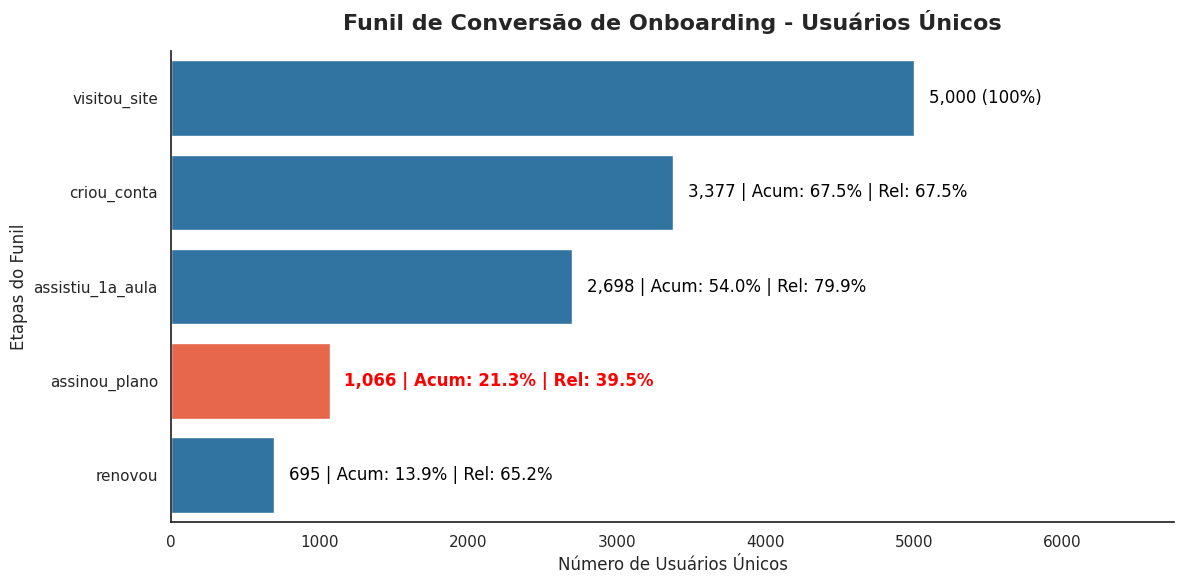

In [48]:
# 6. Plotagem gráfica destacando visualmente o gargalo
plt.figure(figsize=(12, 6))

# Definir as cores: destacar o gargalo em laranja escuro/vermelho e os demais em azul sóbrio
cores = [
    '#ff5733' if etapa == etapa_gargalo else '#1f77b4'
    for etapa in df_funil_metricas['Etapa']
]

# Gerar gráfico de barras horizontais invertendo a ordem para que o topo fique acima
ax = sns.barplot(
    data=df_funil_metricas,
    y='Etapa',
    x='Usuarios',
    palette=cores,
    hue='Etapa',
    legend=False
)

plt.title('Funil de Conversão de Onboarding - Usuários Únicos', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Número de Usuários Únicos', fontsize=12)
plt.ylabel('Etapas do Funil', fontsize=12)

# Adicionar rótulos informativos de conversão nas barras
for i, bar in enumerate(ax.patches):
    qtd = int(bar.get_width())
    pct_topo = df_funil_metricas.iloc[i]['Conversao_Topo (%)']
    pct_ant = df_funil_metricas.iloc[i]['Conversao_Anterior (%)']

    if i == 0:
        texto = f"{qtd:,} (100%)"
    else:
        texto = f"{qtd:,} | Acum: {pct_topo:.1f}% | Rel: {pct_ant:.1f}%"

    ax.text(
        bar.get_width() + 100,
        bar.get_y() + bar.get_height()/2,
        texto,
        va='center',
        ha='left',
        fontweight='bold' if df_funil_metricas.iloc[i]['Etapa'] == etapa_gargalo else 'normal',
        color='red' if df_funil_metricas.iloc[i]['Etapa'] == etapa_gargalo else 'black'
    )

# Ajustar limites do eixo X para dar margem às labels
plt.xlim(0, df_funil_metricas['Usuarios'].max() * 1.35)
sns.despine()
plt.tight_layout()
plt.show()